# Pregunta 2: Mapeo de inundaciones con Sentinel-1 y una U-Net

**Dataset:** [Sen1Floods11](https://github.com/cloudtostreet/Sen1Floods11) (Cloud to Street y NASA).

El objetivo es entrenar desde cero una U-Net en PyTorch que segmente el agua de inundación píxel a píxel a partir de las bandas VV y VH de Sentinel-1. Con experimentos decidimos cómo combinar las etiquetas hechas a mano (doradas) con las automáticas (débiles), comparamos funciones de pérdida y medimos qué tan bien generaliza el modelo a un evento que no se usó para entrenar (Bolivia).

**Datos usados**
- Los 446 chips con etiqueta dorada, con la partición oficial: 252 de entrenamiento, 89 de validación, 90 de test y 15 de Bolivia.
- Todos los chips débiles que no son de Bolivia: 4,160, cada uno con sus dos etiquetas automáticas (Otsu sobre Sentinel-1 e índice espectral de Sentinel-2). El enunciado habla de 4,385 chips débiles, pero en el bucket v1.1 hay 4,384 por carpeta; el objeto que sobra en la carpeta de Sentinel-2 es un archivo `.DS_Store`.
- Los chips de Bolivia (dorados y débiles) no se usan para entrenar ni para elegir hiperparámetros, solo para evaluar.

**Organización**
- Secciones 1 a 7: código del repositorio `sen1floods11_unet/`, que se escribe con `%%writefile`.
- Sección 8: instalación y carpetas de trabajo.
- Sección 9: ejecución completa con `python main.py`.
- Sección 10: resultados de cada entregable.
- Sección 11: empaquetado de la entrega.

| Entregable | Código | Resultados |
|---|---|---|
| 1. U-Net propia con entrada VV + VH | 2.1 | 10.2 |
| 2a. Solo dorados vs. dorados + débiles | 3.2 y 7.1 | 10.3 |
| 2b. BCE vs. Dice vs. combinada | 3.1 y 7.1 | 10.4 |
| 3. Evaluación en eventos vistos (IoU, F1, precisión, recall, matriz de confusión) | 4.1 | 10.5 |
| 4. Generalización a Bolivia | 5.1 y 7.1 | 10.6 |
| 5. Errores característicos del SAR | 5.1 | 10.7 |
| 6. Bono: fusión SAR + Sentinel-2 | 7.1 | 10.8 |

---
## Preparación del entorno
Comprobamos que la sesión de Colab tenga GPU.

In [ ]:
import torch
print("PyTorch", torch.__version__, "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no disponible")
if not torch.cuda.is_available():
    print("No hay GPU: cambiar el tipo de entorno de ejecución a T4 GPU.")

PyTorch 2.11.0+cu130 | GPU: Tesla T4


Las secciones 1 a 7 escriben con `%%writefile` los archivos del repositorio `sen1floods11_unet/`. Primero se crea la carpeta.

In [ ]:
import os
os.makedirs("sen1floods11_unet/src", exist_ok=True)
print("Carpeta creada: sen1floods11_unet/")

Carpeta creada: sen1floods11_unet/


---
## 1. Configuración, descarga de datos y Dataset
### 1.1 `requirements.txt`

In [ ]:
%%writefile sen1floods11_unet/requirements.txt
torch>=2.3
numpy>=1.24
pandas>=2.0
rasterio>=1.3
opencv-python-headless>=4.8
matplotlib>=3.7
tqdm>=4.65
tabulate>=0.9

Writing sen1floods11_unet/requirements.txt


### 1.2 `.gitignore`

In [ ]:
%%writefile sen1floods11_unet/.gitignore
data/
outputs/checkpoints/
*.part
__pycache__/

Writing sen1floods11_unet/.gitignore


### 1.3 `README.md`
Versión inicial; al final de la ejecución `main.py` lo reescribe con la tabla de resultados.

In [ ]:
%%writefile sen1floods11_unet/README.md
# Sen1Floods11: mapeo de inundaciones con una U-Net desde cero (Pregunta 2)

```bash
pip install -r requirements.txt
python main.py
```

`main.py` descarga los datos de `gs://sen1floods11`, entrena, evalúa y reescribe este README con los resultados.

Writing sen1floods11_unet/README.md


### 1.4 `src/__init__.py`
Hace que `src/` sea un paquete, para poder importar sus módulos desde `main.py`.

In [ ]:
%%writefile sen1floods11_unet/src/__init__.py
"""Pregunta 2: Sen1Floods11 con una U-Net desde cero."""

Writing sen1floods11_unet/src/__init__.py


### 1.5 `src/config.py`
Hiperparámetros y opciones del experimento. Por defecto se usan todos los chips débiles (`max_weak = 0`). Cualquier valor se puede cambiar por línea de comandos, por ejemplo `python main.py --epochs 60`.

In [ ]:
%%writefile sen1floods11_unet/src/config.py
"""Hiperparámetros y opciones del experimento (los valores por defecto son los que se usaron en el informe)."""
import argparse
from dataclasses import dataclass, asdict, fields


@dataclass
class Config:
    data_dir: str = "data/sen1floods11"      # carpeta del dataset (misma estructura que el bucket v1.1)
    out_dir: str = "outputs"                 # checkpoints, métricas, figuras e informe
    seed: int = 42
    crop: int = 256               # recorte aleatorio para entrenar, a resolución nativa (10 m)
    batch_size: int = 8
    eval_batch: int = 4           # en evaluación se usa el chip completo de 512x512
    epochs: int = 40              # épocas de los modelos con chips dorados
    weak_epochs: int = 10         # épocas de los modelos dorados + débiles (~4.4k chips por época)
    weak_pretrain_epochs: int = 8 # épocas de pre-entrenamiento solo con débiles
    lr: float = 1e-3
    ft_lr: float = 3e-4
    weight_decay: float = 1e-4
    pos_weight: float = 3.0
    base_ch: int = 32
    depth: int = 4
    max_weak: int = 0             # 0 = todos los chips débiles fuera de Bolivia; >0 = submuestreo
    use_s2_weak: bool = True      # usar también las etiquetas débiles de Sentinel-2 (S2IndexLabelWeak)
    loader_workers: int = 2       # procesos que leen los chips débiles del disco (Colab tiene 2 CPU)
    cloud_max: float = 0.05       # fracción máxima de nubes para considerar un chip S2 como despejado
    run_loss_ablation: bool = True
    run_weak_ablation: bool = True
    run_s2_bonus: bool = True
    download: bool = True
    force_retrain: bool = False
    amp: bool = True              # precisión mixta en GPU
    workers: int = 16             # hilos de descarga
    quick: bool = False           # prueba rápida: pocas épocas y modelo pequeño

    def finalize(self):
        if self.quick:
            self.epochs, self.weak_epochs, self.weak_pretrain_epochs = 2, 1, 1
            self.base_ch, self.crop = 8, 128
        return self

    def as_dict(self):
        return asdict(self)


def parse_args(argv=None) -> Config:
    p = argparse.ArgumentParser(description="Sen1Floods11 - U-Net desde cero (Pregunta 2)")
    for f in fields(Config):
        if f.type in (bool, "bool"):
            p.add_argument(f"--{f.name}", type=lambda s: s.lower() in ("1", "true", "yes", "si", "sí"),
                           default=f.default, metavar="{true,false}")
        else:
            typ = {"int": int, "float": float, "str": str}.get(f.type, f.type) if isinstance(f.type, str) else f.type
            p.add_argument(f"--{f.name}", type=typ, default=f.default)
    return Config(**vars(p.parse_args(argv))).finalize()

Writing sen1floods11_unet/src/config.py


### 1.6 `src/download.py`
Descarga los datos del bucket público `gs://sen1floods11` (no se necesita `gsutil` ni credenciales). Carpetas que se usan:

| Carpeta del bucket | Contenido | Uso |
|---|---|---|
| `HandLabeled/S1Hand` y `LabelHand` | 446 chips dorados: SAR (VV, VH) y máscara manual | entrenamiento, validación, test y Bolivia |
| `HandLabeled/S1OtsuLabelHand` | etiqueta Otsu de esos mismos chips | medir el ruido de las etiquetas débiles |
| `HandLabeled/S2Hand` | Sentinel-2 (13 bandas) de los 446 chips | bono SAR + óptico y figuras de errores |
| `WeaklyLabeled/S1Weak` | SAR de los chips débiles | entrada de los modelos con débiles |
| `WeaklyLabeled/S1OtsuLabelWeak` y `S2IndexLabelWeak` | etiquetas débiles de Sentinel-1 y de Sentinel-2 | entregable 2a |
| `splits/flood_handlabeled` y metadata | partición oficial y datos de cada evento (órbita, fechas) | evaluación |

In [ ]:
%%writefile sen1floods11_unet/src/download.py
"""Descarga de Sen1Floods11 v1.1 desde el bucket público gs://sen1floods11.

Lista los objetos con la API JSON de GCS y los baja por HTTPS en paralelo (no hace falta gsutil ni credenciales).
Se descargan los 446 chips dorados (S1Hand, LabelHand, S1OtsuLabelHand y S2Hand), todos los chips débiles que
no son de Bolivia (S1Weak, S1OtsuLabelWeak y S2IndexLabelWeak; con --max_weak N se puede submuestrear), la
partición oficial (splits/flood_handlabeled) y la metadata de los eventos.
S2Weak (~26 GB) solo se cuenta para el inventario, porque ningún experimento usa Sentinel-2 en los chips débiles.
"""
import json
import os
import re
import shutil
import subprocess
import time
import urllib.parse
import urllib.request
from concurrent.futures import ThreadPoolExecutor, as_completed
from pathlib import Path

import numpy as np
from tqdm.auto import tqdm

GCS_API = os.environ.get("SEN1FLOODS_GCS_API", "https://storage.googleapis.com/storage/v1/b/sen1floods11/o")
GCS_DL = os.environ.get("SEN1FLOODS_GCS_DL", "https://storage.googleapis.com/sen1floods11")
META_GITHUB = "https://raw.githubusercontent.com/cloudtostreet/Sen1Floods11/master/Sen1Floods11_Metadata.geojson"
PREFIX = "v1.1/"
HAND = PREFIX + "data/flood_events/HandLabeled/"
WEAK = PREFIX + "data/flood_events/WeaklyLabeled/"
SPLITS = PREFIX + "splits/flood_handlabeled/"
META = PREFIX + "Sen1Floods11_Metadata.geojson"


def _get(url, retries=5, timeout=60):
    for k in range(retries):
        try:
            with urllib.request.urlopen(url, timeout=timeout) as r:
                return r.read()
        except Exception as e:  # en Colab la red a veces falla: se reintenta esperando cada vez más
            if k == retries - 1:
                raise RuntimeError(f"No se pudo descargar {url}: {e}") from e
            time.sleep(2 ** k)


def _gsutil_list(prefix):
    """Alternativa si la API JSON no responde: gsutil (viene instalado en Colab)."""
    out = subprocess.run(["gsutil", "ls", "-l", f"gs://sen1floods11/{prefix}**"], capture_output=True, text=True, check=True).stdout
    return [(m.group(2), int(m.group(1))) for m in re.finditer(r"^\s*(\d+)\s+\S+\s+gs://sen1floods11/(\S+)$", out, re.M)]


def list_objects(prefix):
    try:
        return _list_objects_api(prefix)
    except Exception as e:
        if shutil.which("gsutil") is None:
            raise
        print(f"  (API JSON no disponible: {e}; uso gsutil)")
        return _gsutil_list(prefix)


def _list_objects_api(prefix):
    items, token = [], None
    while True:
        q = {"prefix": prefix, "fields": "nextPageToken,items(name,size)", "maxResults": 1000}
        if token:
            q["pageToken"] = token
        data = json.loads(_get(f"{GCS_API}?{urllib.parse.urlencode(q)}"))
        items += [(it["name"], int(it["size"])) for it in data.get("items", []) if not it["name"].endswith("/")]
        token = data.get("nextPageToken")
        if not token:
            return items


def list_chips(prefix, inv=None, layer=None):
    """Lista los .tif de una carpeta; los demás objetos (p. ej. un .DS_Store) se anotan en el inventario."""
    objs = list_objects(prefix)
    tifs = [(n, s) for n, s in objs if n.endswith(".tif")]
    if inv is not None:
        inv[layer] = dict(count=len(tifs), bytes=sum(s for _, s in tifs), objetos=len(objs),
                          otros=[Path(n).name for n, _ in objs if not n.endswith(".tif")])
    return tifs


def _local(data_dir, name):
    return Path(data_dir) / name[len(PREFIX):]


def _download_one(name, size, data_dir):
    dst = _local(data_dir, name)
    if dst.exists() and dst.stat().st_size == size:
        return 0
    dst.parent.mkdir(parents=True, exist_ok=True)
    url = f"{GCS_DL}/{urllib.parse.quote(name)}"
    tmp = dst.with_suffix(dst.suffix + ".part")
    try:
        tmp.write_bytes(_get(url))
    except RuntimeError:
        if shutil.which("gsutil") is None:
            raise
        subprocess.run(["gsutil", "-q", "cp", f"gs://sen1floods11/{name}", str(tmp)], check=True)
    tmp.replace(dst)
    return size


def download_objects(objs, data_dir, workers=16, desc="descarga"):
    todo = [(n, s) for n, s in objs if not (_local(data_dir, n).exists() and _local(data_dir, n).stat().st_size == s)]
    if not todo:
        print(f"  {desc}: {len(objs)} archivos ya presentes")
        return
    total = sum(s for _, s in todo)
    with ThreadPoolExecutor(workers) as ex, tqdm(total=total, unit="B", unit_scale=True, desc=desc) as bar:
        futs = [ex.submit(_download_one, n, s, data_dir) for n, s in todo]
        for f in as_completed(futs):
            bar.update(f.result())


def _cid(name):
    return Path(name).name.rsplit("_", 1)[0]


def download_dataset(cfg, need_s2=True):
    """Descarga los datos que usa el proyecto y guarda un inventario del bucket."""
    data_dir = Path(cfg.data_dir)
    data_dir.mkdir(parents=True, exist_ok=True)
    print(f"Descargando Sen1Floods11 v1.1 desde gs://sen1floods11 en {data_dir}")
    inv = {}

    split_objs = list_objects(SPLITS)
    download_objects(split_objs, data_dir, cfg.workers, "splits")

    # chips dorados: SAR, etiqueta manual, etiqueta Otsu del mismo chip y Sentinel-2
    for layer in ["S1Hand", "LabelHand", "S1OtsuLabelHand"] + (["S2Hand"] if need_s2 else []):
        objs = list_chips(HAND + layer + "/", inv, layer)
        download_objects(objs, data_dir, cfg.workers, f"{layer} ({len(objs)})")

    # chips débiles: SAR + etiqueta Otsu (S1) + etiqueta por índice espectral (S2)
    blocked = set()
    for f in (data_dir / "splits" / "flood_handlabeled").glob("*.csv"):
        blocked |= {_cid(line.split(",")[0]) for line in f.read_text().splitlines() if line.strip()}
    s1w = {_cid(n): (n, s) for n, s in list_chips(WEAK + "S1Weak/", inv, "S1Weak")}
    lbw = {_cid(n): (n, s) for n, s in list_chips(WEAK + "S1OtsuLabelWeak/", inv, "S1OtsuLabelWeak")}
    s2w = ({_cid(n): (n, s) for n, s in list_chips(WEAK + "S2IndexLabelWeak/", inv, "S2IndexLabelWeak")}
           if cfg.use_s2_weak else {})
    list_chips(WEAK + "S2Weak/", inv, "S2Weak")             # solo para el inventario, no se descarga
    inv["S2Weak"]["descargado"] = False
    universe = sorted(s1w)
    bol = [c for c in universe if c.startswith("Bolivia")]
    ids = sorted(c for c in universe if c not in blocked and not c.startswith("Bolivia") and (c in lbw or c in s2w))
    inv["weak"] = dict(bucket=len(universe), bolivia_excluidos=len(bol),
                       en_splits_dorados=len([c for c in universe if c in blocked]), usables=len(ids))
    print(f"  chips débiles en el bucket: {len(universe)} | excluidos por ser de Bolivia: {len(bol)} | usables: {len(ids)}")
    if cfg.max_weak and len(ids) > cfg.max_weak:
        ids = sorted(np.random.default_rng(cfg.seed).choice(ids, cfg.max_weak, replace=False).tolist())
        print(f"  submuestreo con --max_weak {cfg.max_weak}: {len(ids)} chips")
    inv["weak"]["usados"] = len(ids)
    (data_dir / "weak_ids_bucket.txt").write_text("\n".join(universe))
    (data_dir / "weak_ids_usados.txt").write_text("\n".join(ids))
    download_objects([s1w[c] for c in ids], data_dir, cfg.workers, f"S1Weak ({len(ids)})")
    download_objects([lbw[c] for c in ids if c in lbw], data_dir, cfg.workers, "S1OtsuLabelWeak")
    if s2w:
        download_objects([s2w[c] for c in ids if c in s2w], data_dir, cfg.workers, "S2IndexLabelWeak")

    # metadata de los eventos (órbita, fechas, chips por evento)
    meta = data_dir / "Sen1Floods11_Metadata.geojson"
    if not meta.exists():
        for url in (f"{GCS_DL}/{META}", META_GITHUB):
            try:
                meta.write_bytes(_get(url))
                break
            except Exception as e:
                print(f"  no se pudo bajar la metadata desde {url}: {e}")
    if meta.exists():
        feats = json.loads(meta.read_text())["features"]
        inv["metadata"] = dict(eventos=len(feats), chips_debiles=int(sum(f["properties"].get("train_chip", 0) for f in feats)),
                               chips_dorados=int(sum(f["properties"].get("val_chip", 0) for f in feats)))
    (data_dir / "inventario_bucket.json").write_text(json.dumps(inv, indent=2))
    print("Descarga completa.")

Writing sen1floods11_unet/src/download.py


### 1.7 `src/data.py`
Lectura de los GeoTIFF, normalización y `Dataset` de PyTorch.
- SAR (VV, VH en dB): los NaN se reemplazan por -50 dB, se recorta a [-50, 1] dB y se escala a [0, 1].
- Un píxel es válido si tiene dato SAR y su etiqueta es 0 o 1. Los píxeles sin dato no entran en la pérdida ni en las métricas.
- Sentinel-2 (solo para el bono): reflectancia TOA dividida entre 10000.
- Para entrenar se usan recortes aleatorios de 256×256 con volteos y rotaciones de 90°; para evaluar, el chip completo de 512×512.
- Los 446 chips dorados se cargan en memoria una sola vez; los 4,160 débiles se leen del disco en cada época.

In [ ]:
%%writefile sen1floods11_unet/src/data.py
"""Lectura, normalización y Dataset de Sen1Floods11.

- SAR en dB: NaN -> -50 dB, recorte a [-50, 1] dB y escala lineal a [0, 1] (igual que el notebook oficial del dataset).
- valid = SAR sin NaN y etiqueta en {0, 1}. El nodata (-1 en la máscara dorada, 255 en las débiles) no entra
  ni en la pérdida ni en las métricas.
- Entrenamiento con recortes aleatorios de 256x256 a resolución nativa (10 m) + volteos/rotaciones; la evaluación
  usa el chip completo de 512x512 (la U-Net es totalmente convolucional).
- Los 446 chips dorados se precargan en RAM (float16); los débiles se leen del disco en cada época porque no
  entran en la RAM de Colab.
"""
from pathlib import Path

import numpy as np
import pandas as pd
import rasterio
import torch
from torch.utils.data import Dataset
from tqdm.auto import tqdm


def chip_id(p):
    """'Ghana_103272_S1Hand.tif' -> 'Ghana_103272'."""
    return Path(p).name.rsplit("_", 1)[0]


def event_of(cid):
    return cid.rsplit("_", 1)[0]


class Paths:
    def __init__(self, data_dir):
        b = Path(data_dir)
        hand, weak = b / "data" / "flood_events" / "HandLabeled", b / "data" / "flood_events" / "WeaklyLabeled"
        self.s1, self.lbl, self.s2 = hand / "S1Hand", hand / "LabelHand", hand / "S2Hand"
        self.otsu_hand = hand / "S1OtsuLabelHand"
        self.s1_weak, self.lbl_weak, self.s2_weak = weak / "S1Weak", weak / "S1OtsuLabelWeak", weak / "S2IndexLabelWeak"
        self.splits = b / "splits" / "flood_handlabeled"
        self.meta = b / "Sen1Floods11_Metadata.geojson"
        self.weak_list = b / "weak_ids_usados.txt"
        self.weak_bucket = b / "weak_ids_bucket.txt"
        self.inventory = b / "inventario_bucket.json"


def build_map(d):
    d = Path(d)
    return {chip_id(p): p for p in sorted(d.glob("*.tif"))} if d.exists() else {}


def read_split(splits_dir, name):
    df = pd.read_csv(Path(splits_dir) / name, header=None)   # los CSV oficiales no tienen encabezado
    return [chip_id(f) for f in df[0]]


def load_splits(paths):
    return dict(train=read_split(paths.splits, "flood_train_data.csv"),
                val=read_split(paths.splits, "flood_valid_data.csv"),
                test=read_split(paths.splits, "flood_test_data.csv"),
                bolivia=read_split(paths.splits, "flood_bolivia_data.csv"))


def normalize_sar(raw):
    img = np.nan_to_num(raw, nan=-50.0, posinf=1.0, neginf=-50.0)
    return ((np.clip(img, -50.0, 1.0) + 50.0) / 51.0).astype(np.float32)


def to_db(x):
    """Inversa de normalize_sar (para analizar la retrodispersión en dB)."""
    return np.asarray(x, np.float32) * 51.0 - 50.0


def load_s2(path):
    """13 bandas S2 L1C (reflectancia TOA x 10000) -> [0, 1] con escala fija."""
    with rasterio.open(path) as src:
        s2 = src.read().astype(np.float32)
    s2 = np.nan_to_num(s2, nan=0.0)
    if s2.max() > 50:
        s2 /= 10000.0
    return np.clip(s2, 0.0, 1.0)


def read_label(path):
    with rasterio.open(path) as src:
        lbl = src.read(1).astype(np.int16)
    return np.where(np.isin(lbl, [0, 1]), lbl, -1).astype(np.int8)


def load_sample(s1_path, lbl_path, s2_path=None):
    with rasterio.open(s1_path) as src:
        raw = src.read().astype(np.float32)               # (2,H,W) [VV, VH] en dB
    img = normalize_sar(raw)
    if s2_path is not None:
        img = np.concatenate([img, load_s2(s2_path)], 0)  # (15,H,W)
    lbl = read_label(lbl_path)
    valid = np.isfinite(raw).all(0) & (lbl != -1)
    return img.astype(np.float16), lbl, valid


class FloodDataset(Dataset):
    """Devuelve (img[C,H,W] float32, lbl[H,W] int64 {-1,0,1}, valid[H,W] bool, chip_id)."""

    def __init__(self, ids, s1m, lblm, s2m=None, crop=None, augment=False, name="", preload=True):
        self.ids, self.crop, self.augment, self.preload = list(ids), crop, augment, preload
        self.paths = [(s1m[c], lblm[c], s2m[c] if s2m is not None else None) for c in self.ids]
        # preload=True carga todo en RAM (chips dorados); con False se lee del disco en cada uso (chips débiles)
        self.data = ([load_sample(*p) for p in tqdm(self.paths, desc=f"cargando {name}", leave=False)]
                     if preload else None)

    def __len__(self):
        return len(self.ids)

    def _random_crop(self, img, lbl, valid):
        H, W = lbl.shape
        S = min(self.crop, H, W)
        for _ in range(10):                                # evita recortes casi sin datos válidos
            i, j = np.random.randint(0, H - S + 1), np.random.randint(0, W - S + 1)
            if valid[i:i + S, j:j + S].mean() > 0.1:
                break
        return img[:, i:i + S, j:j + S], lbl[i:i + S, j:j + S], valid[i:i + S, j:j + S]

    def __getitem__(self, k):
        img, lbl, valid = self.data[k] if self.preload else load_sample(*self.paths[k])
        if self.crop:
            img, lbl, valid = self._random_crop(img, lbl, valid)
        if self.augment:
            if np.random.rand() < 0.5:
                img, lbl, valid = img[:, :, ::-1], lbl[:, ::-1], valid[:, ::-1]
            if np.random.rand() < 0.5:
                img, lbl, valid = img[:, ::-1, :], lbl[::-1, :], valid[::-1, :]
            r = np.random.randint(4)
            if r:
                img, lbl, valid = np.rot90(img, r, (1, 2)), np.rot90(lbl, r), np.rot90(valid, r)
        return (torch.from_numpy(np.ascontiguousarray(img, dtype=np.float32)),
                torch.from_numpy(np.ascontiguousarray(lbl, dtype=np.int64)),
                torch.from_numpy(np.ascontiguousarray(valid)),
                self.ids[k])

Writing sen1floods11_unet/src/data.py


---
## 2. U-Net propia (Entregable 1)
### 2.1 `src/model.py`
U-Net implementada desde cero con capas básicas de `torch.nn`:
- Codificador: bloques `Conv 3×3 → BatchNorm → ReLU` (dos veces) separados por `MaxPool 2×2`; los canales se duplican en cada nivel (32 → 64 → 128 → 256 → 512).
- Decodificador: interpolación bilineal ×2, concatenación con la conexión de salto del mismo nivel y doble convolución.
- Salida: convolución 1×1 con un logit por píxel (la sigmoide da la probabilidad de agua).
- Entrada: 2 canales (VV, VH), o 15 en el bono (SAR + 13 bandas de Sentinel-2).

In [ ]:
%%writefile sen1floods11_unet/src/model.py
"""U-Net implementada desde cero en PyTorch (sin librerías de segmentación).

Encoder: DoubleConv + `depth` bloques (MaxPool 2x2 -> DoubleConv), con base_ch * 2^i canales.
Decoder: upsampling bilineal x2, concatenación con la conexión de salto y DoubleConv.
Salida: conv 1x1 con un logit por píxel (agua); la sigmoide se aplica en la pérdida y en la inferencia.
"""
import torch
import torch.nn as nn
import torch.nn.functional as F


class DoubleConv(nn.Module):
    """(Conv3x3 -> BatchNorm -> ReLU) x 2"""

    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True))

    def forward(self, x):
        return self.block(x)


class Down(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(nn.MaxPool2d(2), DoubleConv(in_ch, out_ch))

    def forward(self, x):
        return self.block(x)


class Up(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.up = nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False)
        self.conv = DoubleConv(in_ch, out_ch)

    def forward(self, x, skip):
        x = self.up(x)
        if x.shape[-2:] != skip.shape[-2:]:
            x = F.interpolate(x, size=skip.shape[-2:], mode="bilinear", align_corners=False)
        return self.conv(torch.cat([skip, x], dim=1))


class UNet(nn.Module):
    def __init__(self, in_channels=2, out_channels=1, base_ch=32, depth=4):
        super().__init__()
        chs = [base_ch * 2 ** i for i in range(depth + 1)]
        self.inc = DoubleConv(in_channels, chs[0])
        self.downs = nn.ModuleList([Down(chs[i], chs[i + 1]) for i in range(depth)])
        self.ups = nn.ModuleList([Up(chs[i + 1] + chs[i], chs[i]) for i in range(depth - 1, -1, -1)])
        self.out_conv = nn.Conv2d(chs[0], out_channels, 1)
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, nonlinearity="relu")
                if m.bias is not None:
                    nn.init.zeros_(m.bias)

    def forward(self, x):
        skips = [self.inc(x)]
        for down in self.downs:
            skips.append(down(skips[-1]))
        x = skips.pop()                      # el nivel más profundo es el cuello de botella
        for up in self.ups:
            x = up(x, skips.pop())
        return self.out_conv(x)


def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

Writing sen1floods11_unet/src/model.py


---
## 3. Pérdidas y entrenamiento (Entregable 2)
### 3.1 `src/losses.py`
Las tres pérdidas del entregable 2b. Todas ignoran los píxeles sin dato.
- BCE con `pos_weight = 3`, porque el agua es la clase minoritaria.
- Dice, que optimiza directamente el solapamiento de la clase agua.
- BCE + Dice, la suma de ambas (es la del modelo base).

In [ ]:
%%writefile sen1floods11_unet/src/losses.py
"""Pérdidas enmascaradas: solo cuentan los píxeles con valid=True."""
import torch
import torch.nn as nn
import torch.nn.functional as F


class MaskedBCE(nn.Module):
    def __init__(self, pos_weight=None):
        super().__init__()
        self.pw = pos_weight

    def forward(self, logits, lbl, valid):
        logits, m = logits.squeeze(1).float(), valid.float()
        pw = torch.tensor(self.pw, device=logits.device) if self.pw else None
        loss = F.binary_cross_entropy_with_logits(logits, (lbl == 1).float(), pos_weight=pw, reduction="none")
        return (loss * m).sum() / m.sum().clamp_min(1.0)


class MaskedDice(nn.Module):
    """1 - Dice de la clase agua, calculado por imagen y promediado en el batch."""

    def __init__(self, smooth=1.0):
        super().__init__()
        self.smooth = smooth

    def forward(self, logits, lbl, valid):
        m = valid.float()
        p = torch.sigmoid(logits.squeeze(1).float()) * m
        t = (lbl == 1).float() * m
        dice = (2 * (p * t).sum((1, 2)) + self.smooth) / (p.sum((1, 2)) + t.sum((1, 2)) + self.smooth)
        return 1 - dice.mean()


class BCEDice(nn.Module):
    def __init__(self, pos_weight=3.0, lambda_dice=1.0):
        super().__init__()
        self.bce, self.dice, self.lam = MaskedBCE(pos_weight), MaskedDice(), lambda_dice

    def forward(self, logits, lbl, valid):
        return self.bce(logits, lbl, valid) + self.lam * self.dice(logits, lbl, valid)

Writing sen1floods11_unet/src/losses.py


### 3.2 `src/train.py`
- AdamW con *cosine annealing* y precisión mixta en GPU.
- Al final de cada época se evalúa en la validación dorada y se guarda la época con mayor IoU. El test y Bolivia no se usan para elegir nada.
- Cada checkpoint guarda una firma con su configuración (arquitectura, épocas, pérdida, número de chips, etc.). Si al volver a ejecutar ya existe un checkpoint con la misma firma, se carga en lugar de reentrenar; si la firma es distinta (por ejemplo, de una prueba rápida), se reentrena.

In [ ]:
%%writefile sen1floods11_unet/src/train.py
"""Entrenamiento: se queda con la época de mayor IoU en la validación dorada y guarda checkpoints reutilizables."""
import random
import time
from copy import deepcopy
from pathlib import Path

import numpy as np
import torch

from .metrics import collect, evaluate_chips
from .model import UNet


def set_seed(s):
    random.seed(s)
    np.random.seed(s)
    torch.manual_seed(s)
    torch.cuda.manual_seed_all(s)


def train_one_epoch(model, loader, opt, crit, device, scaler, use_amp):
    model.train()
    tot = n = 0
    for img, lbl, valid, _ in loader:
        img, lbl, valid = img.to(device, non_blocking=True), lbl.to(device), valid.to(device)
        opt.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device.type, enabled=use_amp):
            logits = model(img)
        loss = crit(logits, lbl, valid)
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(opt)
        scaler.update()
        tot += loss.item() * img.size(0)
        n += img.size(0)
    return tot / max(n, 1)


def load_or_train(cfg, tag, train_loader, val_loader, crit, device, in_ch=2, epochs=None, lr=None,
                  init_state=None, extra_sig=None, log=print):
    """Entrena el modelo o, si ya hay un checkpoint con la misma configuración, lo carga. Devuelve (modelo, historial).

    La firma guarda lo que cambia el resultado (arquitectura, épocas, lr, pérdida, nº de chips...). Si el checkpoint
    tiene otra firma (por ejemplo, de una prueba rápida), se vuelve a entrenar.
    """
    epochs, lr = epochs or cfg.epochs, lr or cfg.lr
    sig = dict(in_ch=in_ch, base_ch=cfg.base_ch, depth=cfg.depth, epochs=epochs, lr=lr, crop=cfg.crop,
               batch_size=cfg.batch_size, weight_decay=cfg.weight_decay, pos_weight=cfg.pos_weight, seed=cfg.seed,
               loss=type(crit).__name__, n_train=len(train_loader.dataset), n_val=len(val_loader.dataset),
               init=init_state is not None, **(extra_sig or {}))
    path = Path(cfg.out_dir) / "checkpoints" / f"{tag}.pt"
    path.parent.mkdir(parents=True, exist_ok=True)
    model = UNet(in_ch, 1, cfg.base_ch, cfg.depth).to(device)
    if path.exists() and not cfg.force_retrain:
        ck = torch.load(path, map_location=device, weights_only=False)
        if ck.get("sig") == sig:
            model.load_state_dict(ck["state"])
            log(f"{tag}: checkpoint cargado (mejor IoU val={ck['best_iou']:.4f})")
            return model, ck["history"]
        log(f"{tag}: el checkpoint guardado tiene otra configuración, se vuelve a entrenar")
    if init_state is not None:
        model.load_state_dict(init_state)
    set_seed(cfg.seed)
    use_amp = cfg.amp and device.type == "cuda"
    scaler = torch.amp.GradScaler(device.type, enabled=use_amp)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=cfg.weight_decay)
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    best, best_state, hist = -1.0, deepcopy(model.state_dict()), []
    for ep in range(1, epochs + 1):
        t0 = time.time()
        tr = train_one_epoch(model, train_loader, opt, crit, device, scaler, use_amp)
        vm, _ = evaluate_chips(collect(model, val_loader, device), 0.5)
        sch.step()
        hist.append(dict(epoch=ep, train_loss=float(tr), val_iou=float(vm["iou"]), val_f1=float(vm["f1"])))
        star = vm["iou"] > best
        if star:
            best, best_state = float(vm["iou"]), deepcopy(model.state_dict())
        log(f"[{tag}] {ep:02d}/{epochs} loss={tr:.4f} | val IoU={vm['iou']:.4f} F1={vm['f1']:.4f} "
            f"P={vm['precision']:.3f} R={vm['recall']:.3f} | {time.time() - t0:.1f}s{' *' if star else ''}")
    model.load_state_dict(best_state)
    torch.save(dict(state=best_state, best_iou=best, history=hist, sig=sig,
                    config=dict(in_channels=in_ch, base_ch=cfg.base_ch, depth=cfg.depth)), path)
    return model, hist


def load_model(cfg, tag, device, in_ch=2):
    path = Path(cfg.out_dir) / "checkpoints" / f"{tag}.pt"
    model = UNet(in_ch, 1, cfg.base_ch, cfg.depth).to(device)
    model.load_state_dict(torch.load(path, map_location=device, weights_only=False)["state"])
    return model.eval()

Writing sen1floods11_unet/src/train.py


---
## 4. Métricas (Entregable 3)
### 4.1 `src/metrics.py`
- IoU agregado (sumando los píxeles de todos los chips) e IoU promedio por chip, que es la métrica que usan los autores del dataset.
- F1, precisión y recall de la clase agua; omisión = 1 − recall y comisión = 1 − precisión. También se guardan TP, FP, FN y TN para la matriz de confusión.
- El umbral de decisión de cada modelo se elige maximizando F1 en validación.
- Intervalo de confianza del IoU al 95 % por bootstrap sobre los chips.

In [ ]:
%%writefile sen1floods11_unet/src/metrics.py
"""Métricas de la clase agua sobre los píxeles válidos.

- IoU agregado: TP / (TP+FP+FN) sumando los píxeles de todos los chips.
- IoU promedio por chip: media del IoU de cada chip (la métrica de los autores de Sen1Floods11); los chips sin agua
  real ni predicha (unión vacía) no entran al promedio.
- Omisión = FN/(TP+FN) = 1 - recall; comisión = FP/(TP+FP) = 1 - precisión.
"""
import numpy as np
import pandas as pd
import torch


def scores(tp, fp, fn, tn):
    p, r = tp / (tp + fp + 1e-9), tp / (tp + fn + 1e-9)
    return dict(iou=tp / (tp + fp + fn + 1e-9), f1=2 * p * r / (p + r + 1e-9), precision=p, recall=r,
                omission=fn / (tp + fn + 1e-9), commission=fp / (tp + fp + 1e-9),
                accuracy=(tp + tn) / max(tp + fp + fn + tn, 1),
                tp=int(tp), fp=int(fp), fn=int(fn), tn=int(tn))


@torch.no_grad()
def collect(model, loader, device):
    """Guarda las probabilidades de cada chip para poder probar varios umbrales sin volver a inferir."""
    model.eval()
    out = []
    for img, lbl, valid, cids in loader:
        prob = torch.sigmoid(model(img.to(device)).float()).squeeze(1).cpu().numpy()
        for j, cid in enumerate(cids):
            out.append(dict(cid=cid, prob=prob[j].astype(np.float16), gt=(lbl[j] == 1).numpy(),
                            valid=valid[j].numpy(), img=img[j].numpy().astype(np.float16)))
    return out


def evaluate_chips(chips, th=0.5):
    TP = FP = FN = TN = 0
    rows = []
    for c in chips:
        v, g = c["valid"], c["gt"] & c["valid"]
        pr = (c["prob"] >= th) & v
        tp, fp = int((pr & g).sum()), int((pr & ~g).sum())
        fn, tn = int((~pr & g).sum()), int((~pr & ~g & v).sum())
        TP, FP, FN, TN = TP + tp, FP + fp, FN + fn, TN + tn
        u = tp + fp + fn
        rows.append(dict(cid=c["cid"], iou=tp / u if u else np.nan, tp=tp, fp=fp, fn=fn, tn=tn,
                         valid_px=int(v.sum()), water_frac=g.sum() / max(v.sum(), 1)))
    res = scores(TP, FP, FN, TN)
    per = pd.DataFrame(rows)
    res["mean_iou_chips"] = float(np.nanmean(per["iou"])) if per["iou"].notna().any() else float("nan")
    return res, per


def sweep_threshold(chips, ths=np.round(np.arange(0.10, 0.91, 0.05), 2)):
    rows = []
    for t in ths:
        r, _ = evaluate_chips(chips, t)
        rows.append(dict(th=float(t), f1=r["f1"], iou=r["iou"], precision=r["precision"], recall=r["recall"]))
    df = pd.DataFrame(rows)
    return float(df.loc[df.f1.idxmax(), "th"]), df


def bootstrap_iou(per, n=2000, seed=0):
    """IC 95 % del IoU agregado remuestreando chips con reemplazo."""
    rng = np.random.default_rng(seed)
    tp, fp, fn = per.tp.values, per.fp.values, per.fn.values
    vals = []
    for _ in range(n):
        k = rng.integers(0, len(per), len(per))
        vals.append(tp[k].sum() / max(tp[k].sum() + fp[k].sum() + fn[k].sum(), 1))
    return float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))

Writing sen1floods11_unet/src/metrics.py


---
## 5. Análisis y figuras (Entregables 4 y 5)
### 5.1 `src/analysis.py`
- Inventario del dataset: compara lo que dice el enunciado (eventos, bandas, tamaño y resolución, número de chips dorados y débiles, valores de la máscara, Bolivia reservada) con los archivos descargados.
- Ruido de las etiquetas débiles: compara la etiqueta Otsu con la dorada en los mismos chips.
- Revisión de imports: comprueba que ningún archivo de `src/` use librerías de segmentación (lo pide el entregable 1).
- Entregable 4: composición del test y de Bolivia (fracción de agua, contraste de VV entre agua y tierra, agua "brillante", órbita) para revisar las hipótesis con datos.
- Entregable 5: cada píxel mal clasificado se asigna a un tipo de error con reglas sobre VV y la distancia al borde del agua:

| Tipo de error | Regla | Causa física probable |
|---|---|---|
| Falso positivo oscuro lejos del agua | VV < −15 dB, a más de 50 m del agua | sombra de radar, superficies lisas |
| Falso negativo brillante | VV > −12 dB | doble rebote urbano, vegetación inundada |
| Error de borde | a menos de 50 m del borde del agua | suelo húmedo, píxeles mixtos |
| Falso negativo con VV intermedio | entre −16 y −12 dB | agua rugosa por viento, turbidez |

Además genera las figuras: curvas de entrenamiento, barrido de umbral, matrices de confusión, comparaciones, brecha, tipos de error y casos de ejemplo.

In [ ]:
%%writefile sen1floods11_unet/src/analysis.py
"""Análisis y figuras: ruido de las etiquetas débiles, composición de los conjuntos, tipos de error del SAR
y nubes en Sentinel-2."""
import json
from pathlib import Path

import cv2
import matplotlib
import rasterio
import numpy as np
import pandas as pd

matplotlib.use("Agg")
import matplotlib.pyplot as plt  # noqa: E402

from .data import event_of, load_s2, read_label, to_db  # noqa: E402

DARK_DB = -15.0     # VV por debajo: retrodispersión típica de agua abierta o superficies lisas
BRIGHT_DB = -12.0   # VV por encima: demasiado brillante para agua abierta (doble rebote, vegetación)
MID_DB = -16.0      # entre MID_DB y BRIGHT_DB: retrodispersión intermedia (agua rugosa o turbia)
NEAR_PX = 5         # 5 px = 50 m del borde del agua real


# --- etiquetas débiles ---
def weak_label_noise(paths, ids):
    """Compara la etiqueta Otsu (S1OtsuLabelHand) con la dorada en los mismos chips."""
    rows = []
    for c in ids:
        po, pg = Path(paths.otsu_hand) / f"{c}_S1OtsuLabelHand.tif", Path(paths.lbl) / f"{c}_LabelHand.tif"
        if not po.exists():
            continue
        g, o = read_label(pg), read_label(po)
        v = (g != -1) & (o != -1)
        gt, ot = (g == 1) & v, (o == 1) & v
        rows.append(dict(cid=c, event=event_of(c), tp=int((gt & ot).sum()), fp=int((~gt & ot & v).sum()),
                         fn=int((gt & ~ot).sum()), agree=int(((gt == ot) & v).sum()), n=int(v.sum())))
    if not rows:
        return None
    df = pd.DataFrame(rows)

    def summ(d):
        tp, fp, fn = d.tp.sum(), d.fp.sum(), d.fn.sum()
        p, r = tp / max(tp + fp, 1), tp / max(tp + fn, 1)
        return pd.Series(dict(chips=len(d), iou=tp / max(tp + fp + fn, 1), precision=p, recall=r,
                              f1=2 * p * r / max(p + r, 1e-9), acuerdo_pixel=d.agree.sum() / max(d.n.sum(), 1)))

    overall = summ(df).to_dict()
    per_event = pd.DataFrame([dict(event=e, **summ(d)) for e, d in df.groupby("event")])
    return dict(overall=overall, per_event=per_event)


# --- composición de los conjuntos ---
def composition(ds, per, name):
    vv_w, vv_l = [], []
    for img, lbl, valid in ds.data:
        db = to_db(img[0])
        vv_w.append(db[(lbl == 1) & valid])
        vv_l.append(db[(lbl == 0) & valid])
    vv_w, vv_l = np.concatenate(vv_w), np.concatenate(vv_l)
    med_w = float(np.median(vv_w)) if vv_w.size else float("nan")
    return dict(conjunto=name, chips=len(ds), eventos=len({event_of(c) for c in ds.ids}),
                frac_agua=float(per.tp.add(per.fn).sum() / max(per.valid_px.sum(), 1)),
                chips_sin_agua=int((per.water_frac == 0).sum()),
                vv_agua_db=med_w, vv_tierra_db=float(np.median(vv_l)), contraste_db=float(np.median(vv_l)) - med_w,
                agua_brillante=float((vv_w > BRIGHT_DB).mean()) if vv_w.size else float("nan"))


def per_event_table(per):
    d = per.assign(event=per.cid.map(event_of)).groupby("event")[["tp", "fp", "fn"]].sum()
    d["iou"] = d.tp / (d.tp + d.fp + d.fn).clip(lower=1)
    d["chips"] = per.assign(event=per.cid.map(event_of)).groupby("event").size()
    return d.reset_index().sort_values("iou")


def load_metadata(path):
    p = Path(path)
    if not p.exists():
        return {}
    feats = json.loads(p.read_text())["features"]
    meta = {f["properties"]["location"]: f["properties"] for f in feats}
    if "Cambodia" in meta:            # los chips del evento de Camboya se llaman "Mekong_<id>"
        meta.setdefault("Mekong", meta["Cambodia"])
    return meta


# --- tipos de error ---
_K = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * NEAR_PX + 1, 2 * NEAR_PX + 1))


def _masks(chip, th):
    v, g = chip["valid"], chip["gt"] & chip["valid"]
    pr = (chip["prob"] >= th) & v
    vv = to_db(chip["img"][0])
    g8 = g.astype(np.uint8)
    near_out = cv2.dilate(g8, _K).astype(bool) & ~g          # franja de 50 m fuera del agua
    near_in = g & ~cv2.erode(g8, _K).astype(bool)             # franja de 50 m dentro del agua
    fp, fn = pr & ~g & v, ~pr & g
    return dict(v=v, g=g, pr=pr, vv=vv, tp=pr & g, fp=fp, fn=fn,
                fp_far_dark=fp & ~near_out & (vv < DARK_DB), fp_edge=fp & near_out,
                fn_bright=fn & (vv > BRIGHT_DB), fn_edge=fn & near_in & ~(vv > BRIGHT_DB),
                fn_mid=fn & ~near_in & (vv > MID_DB) & (vv <= BRIGHT_DB),
                fn_dark=fn & ~near_in & (vv <= MID_DB))


def error_taxonomy(chips, th):
    rows, tot = [], {}
    for c in chips:
        m = _masks(c, th)
        r = dict(cid=c["cid"], water_frac=m["g"].sum() / max(m["v"].sum(), 1))
        for k in ("tp", "fp", "fn", "fp_far_dark", "fp_edge", "fn_bright", "fn_edge", "fn_mid", "fn_dark"):
            r[k] = int(m[k].sum())
            tot[k] = tot.get(k, 0) + r[k]
        rows.append(r)
    df = pd.DataFrame(rows)
    fp, fn = max(tot["fp"], 1), max(tot["fn"], 1)
    breakdown = {
        f"FP oscuros (VV<{DARK_DB:.0f} dB) lejos del agua: sombra/superficie lisa": tot["fp_far_dark"] / fp,
        "FP en el borde del agua (suelo húmedo/píxel mixto)": tot["fp_edge"] / fp,
        f"FP lejos del agua con VV>={DARK_DB:.0f} dB (contexto/agua no etiquetada)": 1 - (tot["fp_far_dark"] + tot["fp_edge"]) / fp,
        f"FN brillantes VV>{BRIGHT_DB:.0f} dB (doble rebote/vegetación inundada)": tot["fn_bright"] / fn,
        "FN en el borde del agua": tot["fn_edge"] / fn,
        f"FN interiores con VV intermedio ({MID_DB:.0f} a {BRIGHT_DB:.0f} dB): agua rugosa/turbia": tot["fn_mid"] / fn,
        f"FN interiores oscuros (VV<={MID_DB:.0f} dB): firma de agua no aprovechada": tot["fn_dark"] / fn,
    }
    return df, breakdown, tot


def select_cases(tax, min_px=30, min_water=0.01):
    """Un chip distinto por tipo de error: el que tiene más píxeles de ese tipo (>= min_px si hay alguno)."""
    used, cases = set(), {}

    def pick(df, col, key):
        df = df[~df.cid.isin(used) & (df[col] > 0)].sort_values(col, ascending=False)
        if len(df):
            good = df[df[col] >= min_px]
            cid = (good if len(good) else df).cid.iloc[0]
            used.add(cid)
            cases[key] = cid

    pick(tax, "fp_far_dark", "A")
    pick(tax[tax.water_frac >= min_water], "fn_bright", "B")
    pick(tax.assign(edge=tax.fp_edge + tax.fn_edge), "edge", "C")
    pick(tax[tax.water_frac >= min_water], "fn_mid", "D")
    return cases


def _nd(a, b):
    return (a - b) / (a + b + 1e-6)


CASE_GROUP = {"A": "fp_far_dark", "B": "fn_bright", "C": "edge", "D": "fn_mid"}


def case_stats(chip, th, s2_path=None, key=None):
    """Mediciones del caso; 'cat' son los píxeles del tipo de error que define el caso (p. ej. FP oscuros lejanos)."""
    m = _masks(chip, th)
    m["edge"] = m["fp_edge"] | m["fn_edge"]
    m["tn"] = m["v"] & ~m["g"] & ~m["pr"]
    m["cat"] = m[CASE_GROUP.get(key, "fp")]
    med = lambda x, k: float(np.median(x[m[k]])) if m[k].any() else float("nan")  # noqa: E731
    out = dict(cid=chip["cid"], group=CASE_GROUP.get(key), vv_tp=med(m["vv"], "tp"), vv_tn=med(m["vv"], "tn"),
               vv_fp=med(m["vv"], "fp"), vv_fn=med(m["vv"], "fn"), vv_cat=med(m["vv"], "cat"),
               n_fp=int(m["fp"].sum()), n_fn=int(m["fn"].sum()), n_tp=int(m["tp"].sum()), n_cat=int(m["cat"].sum()))
    for k in ("fp_far_dark", "fp_edge", "fn_bright", "fn_edge", "fn_mid", "fn_dark"):
        out["n_" + k] = int(m[k].sum())
    if s2_path is not None and Path(s2_path).exists():
        s2 = load_s2(s2_path)
        ndvi, mndwi = _nd(s2[7], s2[3]), _nd(s2[2], s2[11])
        for grp in ("cat", "tp", "tn"):
            out[f"ndvi_{grp}"] = float(np.median(ndvi[m[grp]])) if m[grp].any() else float("nan")
            out[f"mndwi_{grp}"] = float(np.median(mndwi[m[grp]])) if m[grp].any() else float("nan")
    return out


def cloud_fraction(s2_path):
    """Píxel nube = muy brillante en el azul (B2 > 0.2) y en el visible (> 0.25). S2Hand no trae máscara QA."""
    s2 = load_s2(s2_path)
    return float(((s2[1] > 0.2) & (s2[[1, 2, 3]].mean(0) > 0.25)).mean())


# --- figuras ---
def _save(fig, path):
    fig.tight_layout()
    fig.savefig(path, dpi=130, bbox_inches="tight")
    plt.close(fig)
    return str(path)


def fig_curves(histories, path):
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
    for name, h in histories.items():
        if not h:
            continue
        h = pd.DataFrame(h)
        ax[0].plot(h.epoch, h.train_loss, label=name)
        ax[1].plot(h.epoch, h.val_iou, label=name)
    ax[0].set_title("Pérdida de entrenamiento"); ax[1].set_title("IoU en validación dorada (umbral 0.5)")
    for a in ax:
        a.set_xlabel("época"); a.grid(alpha=.3); a.legend(fontsize=7)
    return _save(fig, path)


def fig_sweep(df, th, path):
    fig, ax = plt.subplots(figsize=(6, 3.6))
    for k in ("f1", "iou", "precision", "recall"):
        ax.plot(df.th, df[k], marker="o", ms=3, label=k)
    ax.axvline(th, ls="--", c="k", lw=1); ax.text(th, 0.02, f" umbral={th:.2f}")
    ax.set_xlabel("umbral"); ax.set_title("Barrido de umbral (validación dorada)"); ax.grid(alpha=.3); ax.legend()
    return _save(fig, path)


def fig_confusion(r, th, title, path):
    cm = np.array([[r["tn"], r["fp"]], [r["fn"], r["tp"]]], float)
    pct = cm / cm.sum(1, keepdims=True).clip(min=1) * 100
    fig, ax = plt.subplots(figsize=(5, 4))
    ax.imshow(pct, cmap="Blues", vmin=0, vmax=100)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{int(cm[i, j]):,}\n({pct[i, j]:.1f}%)", ha="center", va="center",
                    color="white" if pct[i, j] > 50 else "black")
    ax.set_xticks([0, 1], ["Pred. no-agua", "Pred. agua"]); ax.set_yticks([0, 1], ["Real no-agua", "Real agua"])
    ax.set_title(f"{title} (umbral {th:.2f})")
    return _save(fig, path)


def fig_bars(df, path, title, metrics=("iou", "mean_iou_chips", "f1")):
    fig, ax = plt.subplots(figsize=(1.6 + 1.9 * len(df), 3.8))
    x, w = np.arange(len(df)), 0.8 / len(metrics)
    for i, k in enumerate(metrics):
        b = ax.bar(x + i * w, df[k], w, label=k)
        ax.bar_label(b, fmt="%.3f", fontsize=7)
    ax.set_xticks(x + w * (len(metrics) - 1) / 2, df["modelo"], rotation=12, ha="right", fontsize=8)
    ax.set_ylim(0, 1); ax.set_title(title); ax.legend(fontsize=8); ax.grid(axis="y", alpha=.3)
    return _save(fig, path)


def fig_gap(rows, path):
    df = pd.DataFrame(rows)
    fig, ax = plt.subplots(figsize=(1.6 + 1.9 * len(df), 3.8))
    x = np.arange(len(df))
    b1 = ax.bar(x - .2, df.test, .4, label="Test (eventos vistos)")
    b2 = ax.bar(x + .2, df.bolivia, .4, label="Bolivia (evento no visto)")
    ax.bar_label(b1, fmt="%.3f", fontsize=7); ax.bar_label(b2, fmt="%.3f", fontsize=7)
    ax.set_xticks(x, df.modelo, rotation=12, ha="right", fontsize=8); ax.set_ylim(0, 1)
    ax.set_ylabel("IoU agregado"); ax.set_title("Generalización geográfica"); ax.legend(fontsize=8)
    return _save(fig, path)


def s2_rgb(s2_path):
    if s2_path is None or not Path(s2_path).exists():
        return None
    s2 = load_s2(s2_path)
    return np.clip(np.stack([s2[3], s2[2], s2[1]], -1) * 3.5, 0, 1)


def fig_case(chip, th, title, path, s2_path=None):
    m = _masks(chip, th)
    err = np.zeros((*m["g"].shape, 3), np.uint8)
    err[m["v"] & ~m["g"] & ~m["pr"]] = (60, 60, 60)
    err[m["tp"]] = (0, 190, 0); err[m["fn"]] = (230, 0, 0); err[m["fp"]] = (255, 165, 0)
    rgb = s2_rgb(s2_path)
    vh = to_db(chip["img"][1])
    fig, ax = plt.subplots(1, 5, figsize=(23, 4.6))
    ax[0].imshow(m["vv"], cmap="gray", vmin=-25, vmax=0); ax[0].set_title("Sentinel-1 VV (dB)")
    ax[1].imshow(vh, cmap="gray", vmin=-30, vmax=-5); ax[1].set_title("Sentinel-1 VH (dB)")
    ax[2].imshow(rgb if rgb is not None else np.zeros_like(err)); ax[2].set_title("Sentinel-2 RGB (contexto)")
    ax[3].imshow(err); ax[3].set_title("verde TP · rojo FN · naranja FP · gris TN · negro sin dato", fontsize=10)
    for a in ax[:4]:
        a.axis("off")
    for k, lab, col in (("tp", "TP", "green"), ("fn", "FN", "red"), ("fp", "FP", "orange")):
        if m[k].sum() > 20:
            ax[4].hist(m["vv"][m[k]], bins=60, range=(-35, 5), density=True, histtype="step", lw=1.5, color=col,
                       label=f"{lab} ({m[k].sum():,} px)")
    tn = m["v"] & ~m["g"] & ~m["pr"]
    if tn.sum() > 20:
        ax[4].hist(m["vv"][tn], bins=60, range=(-35, 5), density=True, histtype="step", color="gray", label="TN")
    ax[4].axvline(DARK_DB, ls=":", c="k"); ax[4].axvline(BRIGHT_DB, ls="--", c="k")
    ax[4].set_xlabel("VV (dB)"); ax[4].legend(fontsize=8); ax[4].set_title("Retrodispersión por tipo de píxel")
    fig.suptitle(f"{title} — {chip['cid']}", fontsize=13)
    return _save(fig, path)


def fig_examples(chips, th, path, n=6, title="Predicciones"):
    chips = sorted(chips, key=lambda c: -c["gt"].sum())[:n]
    fig, ax = plt.subplots(len(chips), 3, figsize=(10, 3.3 * len(chips)))
    ax = np.atleast_2d(ax)
    for i, c in enumerate(chips):
        m = _masks(c, th)
        err = np.zeros((*m["g"].shape, 3), np.uint8)
        err[m["v"] & ~m["g"] & ~m["pr"]] = (60, 60, 60)
        err[m["tp"]] = (0, 190, 0); err[m["fn"]] = (230, 0, 0); err[m["fp"]] = (255, 165, 0)
        ax[i, 0].imshow(m["vv"], cmap="gray", vmin=-25, vmax=0); ax[i, 0].set_title(f"{c['cid']} — VV")
        ax[i, 1].imshow(np.where(m["v"], m["g"], np.nan), cmap="Blues", vmin=0, vmax=1); ax[i, 1].set_title("Etiqueta dorada")
        ax[i, 2].imshow(err); ax[i, 2].set_title("Errores (verde TP, rojo FN, naranja FP, negro sin dato)", fontsize=9)
        for a in ax[i]:
            a.axis("off")
    fig.suptitle(title)
    return _save(fig, path)


def fig_breakdown(breakdown, path):
    k, v = list(breakdown), list(breakdown.values())
    fig, ax = plt.subplots(figsize=(8, 3.6))
    cols = ["#e69f00"] * 3 + ["#d55e00"] * 4
    b = ax.barh(k[::-1], [x * 100 for x in v[::-1]], color=cols[::-1])
    ax.bar_label(b, fmt="%.1f%%", fontsize=8)
    ax.set_xlabel("% de los FP (naranja) o de los FN (rojo) del test"); ax.set_title("Taxonomía de errores")
    ax.tick_params(axis="y", labelsize=8)
    return _save(fig, path)


# --- inventario del dataset ---
EXPECTED = dict(eventos=11, dorados=446, debiles=4385, s2_bandas=13, size=512, res_m=10)


def _raster_props(path):
    with rasterio.open(path) as src:
        a = src.read()
        res_m = abs(src.transform.e) * 111320        # tamaño N-S del píxel (EPSG:4326, de grados a metros)
        return dict(count=src.count, dtype=str(src.dtypes[0]), h=src.height, w=src.width, res_m=float(res_m),
                    crs=str(src.crs), desc=src.descriptions, arr=a)


def _weak_status(n, expected):
    if n == expected:
        return "✔"
    return f"≈ ({n - expected:+d}, ver nota)" if abs(n - expected) <= 1 else "⚠ difiere"


def inventory(P, S, s1m, lblm, s2m, otsum, w1, wl1, wl2, weak_used):
    """Compara las características del dataset que da el enunciado con lo que hay en los datos descargados."""
    E = EXPECTED
    bucket = json.loads(Path(P.inventory).read_text()) if Path(P.inventory).exists() else {}
    cnt = lambda layer, local: bucket.get(layer, {}).get("count", local)  # noqa: E731
    gold = sorted(set(s1m) & set(lblm))
    events = sorted({event_of(c) for c in gold})
    weak_bucket = Path(P.weak_bucket).read_text().split() if Path(P.weak_bucket).exists() else sorted(w1)
    labels_vals = set()
    for c in gold:
        with rasterio.open(lblm[c]) as src:
            labels_vals |= set(np.unique(src.read(1)).tolist())
    r1 = _raster_props(s1m[gold[0]])
    vv = r1["arr"][0][np.isfinite(r1["arr"][0])]
    r2 = _raster_props(s2m[gold[0]]) if s2m else None
    bol_all = [c for c in gold if c.startswith("Bolivia")]
    ok = lambda cond: "✔" if cond else "⚠ difiere"  # noqa: E731
    wb, md = bucket.get("weak", {}), bucket.get("metadata", {})
    md_txt = f" (la metadata oficial suma {md['chips_debiles']:,})" if md.get("chips_debiles") else ""
    n1, n2 = cnt("S1OtsuLabelWeak", len(wl1)), cnt("S2IndexLabelWeak", len(wl2))
    otros2 = bucket.get("S2IndexLabelWeak", {}).get("otros", [])
    s2w = bucket.get("S2Weak", {})
    rows = [
        dict(Característica="Eventos de inundación (chips dorados)", Enunciado=f"{E['eventos']}",
             Encontrado=f"{len(events)}: {', '.join(events)}", Estado=ok(len(events) == E["eventos"])),
        dict(Característica="Bandas Sentinel-1", Enunciado="VV y VH, en dB",
             Encontrado=f"{r1['count']} bandas" + (f" ({', '.join(d for d in r1['desc'] if d)})" if any(r1["desc"]) else "")
                        + f", float32 en dB, VV mediano {np.median(vv):.1f} dB",
             Estado=ok(r1["count"] == 2 and -40 < np.median(vv) < 5)),
        dict(Característica="Bandas Sentinel-2", Enunciado=f"{E['s2_bandas']} bandas espectrales",
             Encontrado=(f"{r2['count']} bandas ({r2['desc'][0]} a {r2['desc'][-1]}, incluye B8A), reflectancia TOA x 10000"
                         if r2 and r2["desc"][0] else f"{r2['count']} bandas") if r2 else "no descargado",
             Estado=ok(r2 is not None and r2["count"] == 13)),
        dict(Característica="Tamaño y resolución de los chips", Enunciado="512×512 px a 10 m, GeoTIFF",
             Encontrado=f"{r1['h']}×{r1['w']} px, píxel de {r1['res_m']:.1f} m ({r1['crs']}), GeoTIFF",
             Estado=ok(r1["h"] == r1["w"] == E["size"] and abs(r1["res_m"] - 10) < 1.0)),
        dict(Característica="Chips con etiqueta dorada", Enunciado=f"{E['dorados']}",
             Encontrado=f"{cnt('LabelHand', len(gold))} en el bucket, {len(gold)} usados "
                        f"(train {len(S['train'])}, valid {len(S['val'])}, test {len(S['test'])}, Bolivia {len(S['bolivia'])})",
             Estado=ok(len(gold) == E["dorados"] and sum(len(v) for v in S.values()) == len(gold))),
        dict(Característica="Valores de la máscara dorada", Enunciado="agua / no agua / sin datos",
             Encontrado=f"{sorted(labels_vals)} (1 agua, 0 no agua, -1 sin datos)", Estado=ok(labels_vals <= {-1, 0, 1})),
        dict(Característica="Chips débiles derivados de Sentinel-1 (Otsu)", Enunciado=f"{E['debiles']:,}",
             Encontrado=f"{n1:,} GeoTIFF en el bucket{md_txt}; {len([c for c in weak_used if c in wl1]):,} usados",
             Estado=_weak_status(n1, E["debiles"])),
        dict(Característica="Chips débiles derivados de Sentinel-2 (índice)", Enunciado=f"{E['debiles']:,}",
             Encontrado=f"{n2:,} GeoTIFF en el bucket"
                        + (f" (+{len(otros2)} archivo no imagen: {', '.join(otros2)})" if otros2 else "")
                        + f"; {len([c for c in weak_used if c in wl2]):,} usados",
             Estado=_weak_status(n2, E["debiles"])),
        dict(Característica="Débiles excluidos por ser de Bolivia", Enunciado="(necesario para el entregable 4)",
             Encontrado=f"{wb.get('bolivia_excluidos', len([c for c in weak_bucket if c.startswith('Bolivia')])):,}",
             Estado="✔"),
        dict(Característica="Bolivia como prueba geográficamente independiente", Enunciado="todos los chips dorados de Bolivia",
             Encontrado=f"{len(S['bolivia'])} de {len(bol_all)} chips dorados de Bolivia están en el split de prueba; "
                        f"0 en train/valid", Estado=ok(sorted(S["bolivia"]) == bol_all)),
        dict(Característica="Métrica de referencia de los autores", Enunciado="IoU promedio sobre los chips + omisión y comisión",
             Encontrado="se reportan (además de IoU agregado, F1, precisión y recall)", Estado="✔"),
    ]
    if s2w.get("count"):
        rows.insert(8, dict(Característica="Imágenes Sentinel-2 de los chips débiles (S2Weak)", Enunciado="(no lo pide ningún entregable)",
                            Encontrado=f"{s2w['count']:,} en el bucket ({s2w['bytes'] / 1e9:.1f} GB); no se descargan porque "
                                       "los modelos con débiles usan SAR como entrada", Estado="—"))
    # tabla por evento
    split_of = {c: k for k, v in S.items() for c in v}
    ev_rows = []
    weak_ev = pd.Series([event_of(c) for c in weak_bucket]).value_counts() if weak_bucket else pd.Series(dtype=int)
    used_ev = pd.Series([event_of(c) for c in weak_used]).value_counts() if weak_used else pd.Series(dtype=int)
    for e in sorted(set(events) | set(weak_ev.index)):
        cs = [c for c in gold if event_of(c) == e]
        ev_rows.append(dict(evento=e, train=sum(split_of.get(c) == "train" for c in cs),
                            valid=sum(split_of.get(c) == "val" for c in cs), test=sum(split_of.get(c) == "test" for c in cs),
                            bolivia=sum(split_of.get(c) == "bolivia" for c in cs), dorados=len(cs),
                            debiles_bucket=int(weak_ev.get(e, 0)), debiles_usados=int(used_ev.get(e, 0))))
    return rows, pd.DataFrame(ev_rows)


def fig_events(ev, path):
    fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
    x = np.arange(len(ev))
    bottom = np.zeros(len(ev))
    for col, c in (("train", "#4c72b0"), ("valid", "#55a868"), ("test", "#c44e52"), ("bolivia", "#8172b2")):
        ax[0].bar(x, ev[col], bottom=bottom, color=c, label=col)
        bottom += ev[col].values
    ax[0].set_xticks(x, ev.evento, rotation=40, ha="right"); ax[0].set_title(f"Chips dorados por evento ({int(ev.dorados.sum())})")
    ax[0].legend(fontsize=8)
    ax[1].bar(x - .2, ev.debiles_bucket, .4, color="#bbbbbb", label="en el bucket")
    ax[1].bar(x + .2, ev.debiles_usados, .4, color="#dd8452", label="usados")
    ax[1].set_xticks(x, ev.evento, rotation=40, ha="right")
    ax[1].set_title(f"Chips débiles por evento ({int(ev.debiles_bucket.sum()):,} en el bucket, {int(ev.debiles_usados.sum()):,} usados)")
    ax[1].legend(fontsize=8)
    return _save(fig, path)


def forbidden_imports(src_dir):
    """Busca imports de librerías de segmentación en src/ (el entregable 1 pide no usarlas)."""
    bad = ("segmentation_models", "torchvision.models.segmentation", "monai", "smp.", "mmseg", "detectron2")
    hits = []
    for f in Path(src_dir).rglob("*.py"):
        for i, line in enumerate(f.read_text(encoding="utf-8").splitlines(), 1):
            if line.lstrip().startswith(("import", "from")) and any(b in line for b in bad):
                hits.append(f"{f.name}:{i}")
    return hits

Writing sen1floods11_unet/src/analysis.py


---
## 6. Análisis escrito, README e informe
### 6.1 `src/report.py`
A partir de `resultados.json` escribe:
- `outputs/analisis.md`: el análisis de cada entregable que se muestra en la Sección 10.
- El `README.md` del repositorio con la tabla de resultados.
- `outputs/informe/informe_p2.tex`: el informe en LaTeX (plantilla NeurIPS) con sus figuras.

Los números y algunas conclusiones salen de los resultados de la corrida; por ejemplo, el texto del bono cambia según si la fusión con Sentinel-2 mejora o no el IoU.

In [ ]:
%%writefile sen1floods11_unet/src/report.py
"""Genera, a partir de resultados.json, el análisis en Markdown, el README con resultados y el informe en
LaTeX (plantilla NeurIPS). Los textos usan los números de la corrida, así que cambian si cambian los resultados."""
import math
import re
import shutil
from pathlib import Path

import pandas as pd

from .analysis import BRIGHT_DB, DARK_DB, MID_DB

REPO = Path(__file__).resolve().parents[1]
KEYS = [("iou", "IoU"), ("mean_iou_chips", "IoU medio/chip"), ("f1", "F1"), ("precision", "Precisión"),
        ("recall", "Recall"), ("omission", "Omisión"), ("commission", "Comisión")]


def f3(x):
    return "n/d" if x is None or (isinstance(x, float) and math.isnan(x)) else f"{x:.3f}"


def pc(x):
    return "n/d" if x is None or (isinstance(x, float) and math.isnan(x)) else f"{100 * x:.1f} %"


def ep(n):
    return f"{n} época" if n == 1 else f"{n} épocas"


def db(x):
    return "n/d" if x is None or (isinstance(x, float) and math.isnan(x)) else f"{x:.1f} dB"



# ============================================================================ resumen por entregable
def checklist(R):
    """Una fila por cada punto del enunciado, con el resultado obtenido en esta corrida."""
    M, D, V = R["models"], R["data"], R.get("verificacion", {})
    fin = R["final_model"]
    F = M[fin]
    rows = []
    add = lambda e, req, ev: rows.append(dict(Entregable=e, Requisito=req, Resultado=ev))  # noqa: E731
    libs = V.get("seg_libs", [])
    add("1", "U-Net propia en PyTorch",
        f"`src/model.py`: clases DoubleConv, Down, Up y UNet, {R['n_params'] / 1e6:.2f} M de parámetros")
    add("1", "Sin librerías de segmentación",
        "Revisión de los imports de `src/`: " + ("no se usa ninguna" if not libs else ", ".join(libs)))
    add("1", "Entrada con las dos bandas SAR (VV, VH)", "`in_channels=2` (VV, VH en dB); 15 canales en el bono")
    weak = R["groups"].get("weak", [])
    add("2a", "Entrenar solo con los chips dorados",
        f"Modelo «Solo dorados · BCE+Dice»: {D['train']} chips de train y {D['val']} de validación (los {D['test']} de "
        f"test y {D['bolivia']} de Bolivia quedan para evaluar; en total {D['train'] + D['val'] + D['test'] + D['bolivia']})")
    add("2a", "Añadir los chips con etiqueta débil",
        f"{D.get('weak_s1', 0):,} chips débiles S1 (Otsu) y {D.get('weak_s2', 0):,} S2 (índice): "
        + "; ".join(weak[1:]) if weak else "no se ejecutó")
    if weak:
        bw = max(weak, key=lambda n: M[n]["val"]["iou"])
        add("2a", "Decidir cómo combinar ambas fuentes",
            f"Mejor estrategia por IoU de validación: «{bw}» (val {M[bw]['val']['iou']:.3f}, test {M[bw]['test']['iou']:.3f})")
    loss = R["groups"].get("loss", [])
    if loss:
        bl = max(loss, key=lambda n: M[n]["val"]["iou"])
        add("2b", "BCE vs. Dice vs. combinada",
            "IoU en test: " + ", ".join(f"{n.split('· ')[1]} {M[n]['test']['iou']:.3f}" for n in loss)
            + f". Mejor en validación: {bl.split('· ')[1]}")
    else:
        add("2b", "BCE vs. Dice vs. combinada", "no se ejecutó")
    t = F["test"]
    add("3", "Evaluar en chips dorados de eventos vistos",
        f"Test oficial: {D['test']} chips; todos sus eventos están en train: {'sí' if V.get('test_events_seen') else 'no'}")
    add("3", "IoU, F1, precisión y recall de la clase agua",
        f"IoU {t['iou']:.3f}, F1 {t['f1']:.3f}, precisión {t['precision']:.3f}, recall {t['recall']:.3f} "
        f"(IoU medio por chip {t['mean_iou_chips']:.3f}; omisión {t['omission']:.3f}; comisión {t['commission']:.3f})")
    add("3", "Matriz de confusión comentada", "Figura de la matriz y comentario con los conteos (sección del entregable 3)")
    add("4", "Entrenar sin Bolivia",
        f"Chips de Bolivia usados al entrenar: {V.get('bolivia_train', 0)} de train, {V.get('bolivia_val', 0)} de "
        f"validación y {V.get('bolivia_weak', 0)} débiles")
    add("4", "Evaluar solo en los chips dorados de Bolivia",
        f"{V.get('bolivia_eval', D['bolivia'])} chips de `flood_bolivia_data.csv` (partición oficial)")
    b = F["bolivia"]
    lo, hi = F["bolivia_ci"]
    add("4", "Brecha frente al punto 3",
        f"IoU test {t['iou']:.3f} vs. Bolivia {b['iou']:.3f} (diferencia {b['iou'] - t['iou']:+.3f}; IC 95 % en Bolivia "
        f"{lo:.3f}-{hi:.3f})")
    add("4", "Al menos dos hipótesis",
        "5 hipótesis (composición, contraste, cobertura del suelo, geometría de adquisición y tamaño de muestra), "
        "revisadas con datos")
    cases = R.get("cases", {})
    add("5", "Al menos tres tipos de error del SAR",
        f"{len(cases)} tipos: " + "; ".join(c["title"].split(") ", 1)[1] for c in cases.values()))
    add("5", "Ejemplos visuales",
        f"{sum(1 for k in R['figures'] if k.startswith('caso_'))} figuras (VV, VH, Sentinel-2, mapa de errores, histograma)")
    s2 = R["groups"].get("s2", [])
    if len(s2) == 2:
        d = M[s2[1]]["test"]["iou"] - M[s2[0]]["test"]["iou"]
        add("6 (bono)", "Bandas de Sentinel-2 como canales extra", "U-Net de 15 canales: VV, VH y las 13 bandas S2")
        add("6 (bono)", "Solo chips sin nubes",
            f"{R['s2']['clear']['train']} de train, {R['s2']['clear']['val']} de validación y {R['s2']['clear']['test']} "
            f"de test con menos de {100 * R['s2']['cloud_max']:.0f} % de nubes")
        add("6 (bono)", "Medir si la fusión mejora el IoU",
            f"Mismos chips: SAR {M[s2[0]]['test']['iou']:.3f} vs. SAR+S2 {M[s2[1]]['test']['iou']:.3f} (ΔIoU {d:+.3f})")
    return rows


# ============================================================================ bloques de contenido
def build_blocks(R):
    B = []
    h = lambda t, lvl=2: B.append(("h", lvl, t))          # noqa: E731
    p = lambda t: B.append(("p", t))                      # noqa: E731
    ul = lambda items, tex=True: B.append(("ul", items, tex))  # noqa: E731
    fig = lambda key, cap: B.append(("fig", key, cap)) if key in R["figures"] else None  # noqa: E731
    M, cfg, D = R["models"], R["config"], R["data"]
    fin = R["final_model"]
    F = M[fin]
    t = F["test"]
    tot = t["tp"] + t["fp"] + t["fn"] + t["tn"]
    wf = (t["tp"] + t["fn"]) / max(tot, 1)
    lo, hi = F["test_ci"]

    CHK = pd.DataFrame(checklist(R))

    h("Resumen por entregable")
    p("Qué se hizo para cada punto del enunciado y el resultado principal. El detalle está en las secciones siguientes.")
    B.append(("table", CHK, "Puntos del enunciado y resultado obtenido.", False))

    def table(names, split="test", cap="", tex=True):
        rows = [dict(Modelo=n, Umbral=f"{M[n]['threshold']:.2f}", **{lab: f3(M[n][split][k]) for k, lab in KEYS})
                for n in names if n in M]
        B.append(("table", pd.DataFrame(rows), cap, tex))

    # --- datos y ruido de las etiquetas débiles
    h("Contexto: Inventario del dataset y ruido de las etiquetas débiles")
    p("Comparación entre las características de Sen1Floods11 que da el enunciado y lo que se encontró al descargar "
      "los datos.")
    if R.get("inventario"):
        B.append(("table", pd.DataFrame(R["inventario"]), "Características del dataset: enunciado vs. datos descargados."))
    bk = R.get("bucket", {})
    n_w, n_md = bk.get("S1Weak", {}).get("count"), bk.get("metadata", {}).get("chips_debiles")
    otros = bk.get("S2IndexLabelWeak", {}).get("otros", [])
    if n_w and n_w != 4385:
        p(f"**Número de chips débiles.** El enunciado y el artículo original hablan de 4,385 chips débiles, pero el "
          f"bucket v1.1 tiene {n_w:,} GeoTIFF en cada carpeta de chips débiles"
          + (f", lo mismo que suma la metadata oficial del dataset ({n_md:,})" if n_md else "")
          + (f". La carpeta de etiquetas de Sentinel-2 tiene {n_w + len(otros):,} objetos, pero {len(otros)} no es una "
             f"imagen ({', '.join(otros)})" if otros else "")
          + ". Se usan todos los chips débiles disponibles menos los de Bolivia.")
    if R.get("eventos"):
        evd = pd.DataFrame(R["eventos"])
        B.append(("table", evd.rename(columns=dict(evento="Evento", dorados="Dorados", debiles_bucket="Débiles (bucket)",
                                                   debiles_usados="Débiles (usados)", orbita="Órbita", fecha_s1="Fecha S1")),
                  "Chips por evento de inundación y partición.", False))
        solo_debiles = [e for e, d in zip(evd.evento, evd.dorados) if d == 0]
        p(f"Los chips dorados cubren {int((evd.dorados > 0).sum())} eventos y suman {int(evd.dorados.sum())}; de los "
          f"{int(evd.debiles_bucket.sum()):,} chips débiles del bucket se usan {int(evd.debiles_usados.sum()):,}. "
          + ((f"{solo_debiles[0]} solo tiene chips débiles. " if len(solo_debiles) == 1 else
              f"{', '.join(solo_debiles)} solo tienen chips débiles. ") if solo_debiles else "")
          + "Los chips débiles de Bolivia se dejan fuera para que el entregable 4 mida la generalización a un evento "
            "que el modelo de verdad no vio.")
    fig("eventos", "Chips dorados por evento y partición (izquierda) y chips débiles por evento (derecha).")
    p(f"Partición oficial: {D['train']} chips dorados de entrenamiento, {D['val']} de validación, {D['test']} de "
      f"test (eventos vistos) y {D['bolivia']} de Bolivia (evento reservado). Para el entregable 2a se usan "
      f"{D.get('weak_s1', 0):,} chips débiles con etiqueta Otsu de Sentinel-1 y {D.get('weak_s2', 0):,} con etiqueta "
      "por índice espectral de Sentinel-2, que son las dos fuentes de etiquetas débiles del dataset.")
    wn = R.get("weak_noise")
    if wn:
        o = wn["overall"]
        sesgo = ("marca más agua de la que realmente hay (más comisión que omisión)" if o["precision"] < o["recall"]
                 else "marca menos agua de la que realmente hay (más omisión que comisión)")
        pe = pd.DataFrame(wn["per_event"]).sort_values("iou")
        p(f"**Ruido de las etiquetas débiles.** El dataset también trae la etiqueta Otsu de los chips dorados "
          f"(S1OtsuLabelHand), así que se puede comparar directamente con la etiqueta manual: IoU = {f3(o['iou'])}, "
          f"precisión = {f3(o['precision'])} y recall = {f3(o['recall'])} en {int(o['chips'])} chips (coinciden en el "
          f"{pc(o['acuerdo_pixel'])} de los píxeles). En otras palabras, la umbralización {sesgo}. El ruido cambia bastante entre "
          f"eventos: el peor es {pe.iloc[0]['event']} (IoU {f3(pe.iloc[0]['iou'])}) y el mejor {pe.iloc[-1]['event']} "
          f"(IoU {f3(pe.iloc[-1]['iou'])}). Las etiquetas débiles son muchas pero imperfectas, y eso es lo que se pone a "
          f"prueba en el entregable 2a. Para las etiquetas débiles de Sentinel-2 el dataset no trae una versión sobre los "
          f"chips dorados, así que su calidad solo se puede ver de forma indirecta en los resultados del 2a.")

    # --- modelo
    h("Entregable 1: U-Net propia y entrenamiento")
    p(f"La U-Net está escrita desde cero en PyTorch, sin librerías de segmentación. Tiene {cfg['depth']} niveles de "
      f"submuestreo, {cfg['base_ch']} canales en el primer nivel y {R['n_params'] / 1e6:.2f} M de parámetros. Como "
      f"entrada usa VV y VH en dB, normalizados a [0, 1]. Se entrena con recortes aleatorios de {cfg['crop']}x{cfg['crop']} px "
      f"a resolución nativa (10 m), volteos y rotaciones de 90°, y se evalúa sobre el chip completo de 512x512. "
      f"Optimizador AdamW (lr={cfg['lr']}, weight decay={cfg['weight_decay']}) con cosine annealing, "
      f"{ep(cfg['epochs'])} por modelo y batch de {cfg['batch_size']}. Los píxeles sin dato (SAR vacío o etiqueta -1) "
      f"no cuentan en la pérdida ni en las métricas. De cada modelo se guarda la época con mayor IoU en la validación "
      f"dorada, y el umbral de decisión se elige maximizando F1 en validación; el test y Bolivia solo se usan para "
      f"reportar. El modelo final es el de mayor IoU en validación: **{fin}**.")
    fig("curvas", "Curvas de entrenamiento: pérdida y IoU de validación por época de cada modelo.")

    # --- 2a
    if "weak" in R["groups"]:
        names = R["groups"]["weak"]
        h("Entregable 2a: Solo dorados vs. dorados + débiles")
        p(f"Todas las estrategias usan la misma U-Net y la pérdida BCE+Dice, y se validan y evalúan solo con chips "
          f"dorados: (1) solo los chips dorados de entrenamiento; (2) dorados + {D.get('weak_s1', 0):,} chips débiles "
          f"con etiqueta Otsu de Sentinel-1; (3) dorados + {D.get('weak_s2', 0):,} chips débiles con etiqueta por índice "
          f"de Sentinel-2; (4) pre-entrenamiento con los débiles S1 y ajuste final con los dorados. Con los débiles cada "
          f"época tiene ~{D.get('weak_s1', 0) + D['train']:,} chips, por eso estos modelos se entrenan "
          f"{ep(cfg.get('weak_epochs', 0))} en lugar de {cfg['epochs']} (aun así hacen más pasos de optimización).")
        table(names, "test", "Estrategias de supervisión evaluadas en el test (eventos vistos).")
        table(names, "bolivia", "Las mismas estrategias evaluadas en Bolivia (evento no visto).", tex=False)
        fig("ablacion_debiles", "Entregable 2a: IoU en test de cada estrategia de supervisión.")
        g = M["Solo dorados · BCE+Dice"]
        lines = []
        for n in names[1:]:
            dt, dbv = M[n]["test"]["iou"] - g["test"]["iou"], M[n]["bolivia"]["iou"] - g["bolivia"]["iou"]
            lines.append(f"**{n}** frente a solo dorados: ΔIoU test {dt:+.3f}, ΔIoU Bolivia {dbv:+.3f}, "
                         f"IoU de validación {f3(M[n]['val']['iou'])} (solo dorados: {f3(g['val']['iou'])})")
        ul(lines)
        bv = max(names, key=lambda n: M[n]["val"]["iou"])
        wfrac, wfrac2 = R["data"].get("weak_water_frac"), R["data"].get("weak_s2_water_frac")
        s1n, s2n = "Dorados + débiles S1 (Otsu)", "Dorados + débiles S2 (índice)"
        comp = ""
        if s1n in M and s2n in M:
            mejor = s1n if M[s1n]["val"]["iou"] >= M[s2n]["val"]["iou"] else s2n
            comp = (f"De las dos fuentes de etiquetas débiles, las **{mejor.split('+ ')[1]}** dan mejor resultado en validación "
                    f"({f3(M[s1n]['val']['iou'])} S1 vs. {f3(M[s2n]['val']['iou'])} S2). Una explicación es que las "
                    "etiquetas S1 salen del mismo radar y heredan sus errores (sombras, doble rebote), que el modelo termina "
                    "aprendiendo; las S2 no dependen del radar, aunque sí de que la escena óptica esté despejada y de que "
                    "su fecha coincida con la del SAR. ")
        p(f"Según la validación, la mejor estrategia es **{bv}**. "
          + (f"Las etiquetas débiles S1 tienen en promedio {pc(wfrac)} de agua"
             + (f" (S2: {pc(wfrac2)})" if wfrac2 is not None else "")
             + (f" y la etiqueta Otsu tiene un IoU de {f3(wn['overall']['iou'])} frente a la etiqueta manual" if wn else "")
             + ": aportan muchos más ejemplos y más variedad de eventos, pero con errores sistemáticos en bordes, sombras "
               "y vegetación. " if wfrac is not None else "")
          + comp
          + "La idea del pre-entrenamiento con ajuste es aprovechar la cantidad de datos débiles para aprender patrones "
            "generales de retrodispersión y dejar que al final las etiquetas manuales corrijan los sesgos de la "
            "umbralización; al mezclarlos con los dorados, en cambio, el modelo ve ese ruido durante todo el entrenamiento. "
          + ("En nuestros resultados la supervisión débil **mejora** al modelo que solo usa chips dorados, así que vale "
             "la pena usarla." if bv != "Solo dorados · BCE+Dice" else
             "En nuestros resultados ninguna estrategia con débiles supera en validación al modelo que solo usa chips "
             "dorados: con este número de épocas pesa más el ruido que la cantidad extra de datos."))

    # --- 2b
    if "loss" in R["groups"]:
        names = R["groups"]["loss"]
        h("Entregable 2b: BCE vs. Dice vs. BCE+Dice")
        table(names, "test", "Comparación de pérdidas (solo chips dorados, mismas épocas; umbral elegido en validación).")
        fig("ablacion_perdida", "Comparación de pérdidas en test.")
        bv = max(names, key=lambda n: M[n]["val"]["iou"])
        bt = max(names, key=lambda n: M[n]["test"]["iou"])
        bce, dice = M.get("Solo dorados · BCE"), M.get("Solo dorados · Dice")
        if bv == bt:
            txt = (f"**{bv}** es el mejor tanto en validación, que es el criterio de selección (IoU "
                   f"{f3(M[bv]['val']['iou'])}), como en test (IoU {f3(M[bt]['test']['iou'])}). ")
        else:
            txt = (f"En validación, que es el criterio de selección, gana **{bv}** (IoU {f3(M[bv]['val']['iou'])}); en "
                   f"test el mejor es **{bt}** (IoU {f3(M[bt]['test']['iou'])}). ")
        if bce and dice:
            txt += (f"La BCE con pos_weight={cfg['pos_weight']} logra precisión {f3(bce['test']['precision'])} y recall "
                    f"{f3(bce['test']['recall'])}, y la Dice {f3(dice['test']['precision'])} y "
                    f"{f3(dice['test']['recall'])}. La BCE promedia el error de todos los píxeles y, como hay "
                    f"~{round(1 / max(wf, 1e-3))} píxeles válidos por cada píxel de agua, sin el pos_weight su gradiente "
                    "quedaría dominado por la tierra. La Dice mide directamente el solapamiento de la clase agua y no "
                    "depende de los verdaderos negativos, así que en principio maneja mejor el desbalance. La combinación "
                    "busca juntar el gradiente estable de la BCE con el enfoque en el solapamiento de la Dice.")
        p(txt)

    # --- evaluación en distribución
    h("Entregable 3: Evaluación en distribución (test, eventos vistos)")
    table([fin], "test", f"Métricas de la clase agua en test del modelo final (umbral {F['threshold']:.2f}).")
    fig("umbral", "Barrido del umbral de decisión en validación; la línea discontinua marca el umbral elegido.")
    fig("confusion", "Matriz de confusión por píxel en el test (conteos y porcentaje por fila).")
    dom = ("la **omisión** (agua que no se detecta) es mayor que la comisión, así que el modelo es conservador"
           if t["omission"] > t["commission"] else
           "la **comisión** (falsas alarmas) es mayor que la omisión, así que el modelo tiende a marcar agua de más")
    p(f"**Comentario de la matriz de confusión.** El agua es solo el {pc(wf)} de los {tot:,} píxeles válidos del test, "
      f"así que la exactitud no dice mucho: un modelo que nunca predijera agua tendría {pc(1 - wf)} de exactitud (el "
      f"nuestro tiene {pc(t['accuracy'])}). Por eso usamos métricas de la clase agua. De cada 100 píxeles de agua real el "
      f"modelo detecta {round(100 * t['recall'])} y se le escapan {round(100 * t['omission'])}; de cada 100 píxeles que "
      f"marca como agua, {round(100 * t['precision'])} lo son. Hay {t['fp'] / max(t['tp'], 1):.2f} falsos positivos por "
      f"cada verdadero positivo y {dom}. El IoU agregado es {f3(t['iou'])} (IC 95 % por bootstrap sobre chips: "
      f"{f3(lo)}-{f3(hi)}) y el IoU promedio por chip es {f3(t['mean_iou_chips'])}"
      + (": la diferencia indica que al modelo le va bien en los chips con mucha agua y peor en los que tienen poca, que "
         "en el promedio por chip pesan lo mismo." if t["iou"] - t["mean_iou_chips"] > 0.05 else
         ": son parecidos, así que el desempeño es similar en chips con poca y con mucha agua.")
      )
    ev = pd.DataFrame(R.get("per_event_test", []))
    if len(ev):
        ev = ev.sort_values("iou")
        B.append(("table", ev.assign(iou=ev.iou.map(f3))[["event", "chips", "iou", "orbita"]]
                  .rename(columns=dict(event="Evento", chips="Chips", iou="IoU", orbita="Órbita S1")),
                  "IoU agregado del modelo final por evento de inundación en el test.", False))
        p(f"El evento más difícil es **{ev.iloc[0]['event']}** (IoU {f3(ev.iloc[0]['iou'])}) y el más fácil "
          f"**{ev.iloc[-1]['event']}** (IoU {f3(ev.iloc[-1]['iou'])}).")
    fig("ejemplos_test", "Ejemplos del test: VV, etiqueta dorada y mapa de errores.")

    # --- Bolivia
    h("Entregable 4: Generalización geográfica (Bolivia)")
    b = F["bolivia"]
    blo, bhi = F["bolivia_ci"]
    gap = b["iou"] - t["iou"]
    flat = abs(gap) < 0.01
    rows = [dict(Métrica=lab, Test=f3(t[k]), Bolivia=f3(b[k]), Brecha=f"{b[k] - t[k]:+.3f}")
            for k, lab in KEYS[:5]]
    B.append(("table", pd.DataFrame(rows), f"Brecha de generalización del modelo final, {fin}."))
    fig("brecha", "IoU en test y en Bolivia de todos los modelos.")
    fig("ejemplos_bolivia", "Ejemplos de Bolivia: VV, etiqueta dorada y mapa de errores.")
    overlap = not (bhi < lo or hi < blo)
    p(f"Siguiendo la partición oficial, ningún chip de Bolivia (dorado o débil) se usó para entrenar ni para elegir "
      f"hiperparámetros. El IoU en Bolivia es {f3(b['iou'])} (IC 95 %: {f3(blo)}-{f3(bhi)}) y en el test "
      f"{f3(t['iou'])}, una brecha de {gap:+.3f}. "
      + ("Los intervalos de confianza se solapan, así que con solo "
         f"{R['data']['bolivia']} chips la diferencia no es estadísticamente concluyente. " if overlap else
         "Los intervalos de confianza no se solapan, así que la diferencia se mantiene aunque cambien los chips. ")
      + ("En la práctica el modelo rinde igual en Bolivia que en los eventos vistos, aunque nunca vio esa zona al "
         "entrenar." if flat else
         "Contra lo esperado, el modelo rinde **mejor** en el evento no visto; abajo se revisa por qué." if gap > 0 else
         "Como era de esperar, el rendimiento **baja** en el evento que no se vio al entrenar."))
    comp = {c["conjunto"]: c for c in R["composition"]}
    ct, cb = comp["test"], comp["bolivia"]
    B.append(("table", pd.DataFrame([dict(Conjunto=c["conjunto"], Chips=c["chips"], Eventos=c["eventos"],
                                          **{"Frac. agua": pc(c["frac_agua"]), "Chips sin agua": c["chips_sin_agua"],
                                             "VV agua": db(c["vv_agua_db"]), "VV tierra": db(c["vv_tierra_db"]),
                                             "Contraste": db(c["contraste_db"]),
                                             "Agua brillante": pc(c["agua_brillante"])}) for c in (ct, cb)]),
              "Composición del test y de Bolivia (datos para revisar las hipótesis)."))
    bm = R.get("bolivia_meta", {})
    worst = ev.iloc[0] if len(ev) else None

    def verdict(favors_bol, negligible):
        if negligible:
            return " La diferencia es pequeña, así que este factor por sí solo no explica la brecha."
        if flat:
            return (" Este factor favorece a Bolivia y puede compensar que sea un evento nuevo." if favors_bol else
                    " Este factor perjudica a Bolivia; que el IoU no baje sugiere que otros factores lo compensan.")
        if favors_bol == (gap > 0):
            return " Va en el mismo sentido que la brecha observada, así que es una explicación posible."
        return " Va en sentido contrario a la brecha observada, así que no la explica (sin este factor la brecha sería mayor)."

    fw_t, fw_b = ct["frac_agua"], cb["frac_agua"]
    c_t, c_b = ct["contraste_db"], cb["contraste_db"]
    ab_t, ab_b = ct["agua_brillante"], cb["agua_brillante"]
    hyp = [
        f"**Composición y tamaño de los cuerpos de agua.** Fracción de agua: test {pc(fw_t)} vs. Bolivia {pc(fw_b)}; chips "
        f"sin agua: {ct['chips_sin_agua']} vs. {cb['chips_sin_agua']}. Las superficies de agua grandes y continuas (como las "
        "llanuras inundadas de la Amazonía boliviana) son más fáciles de segmentar que los parches pequeños, porque los "
        "errores de borde pesan menos frente al área total; y en un chip sin agua solo se pueden cometer falsas alarmas."
        + verdict(fw_b > fw_t, abs(fw_b - fw_t) < 0.1 * max(fw_t, 1e-6)),
        f"**Contraste radiométrico.** Diferencia mediana de VV entre tierra y agua: {db(c_t)} en test vs. {db(c_b)} en "
        "Bolivia. Con más contraste, el agua (lisa y oscura) se separa mejor de la tierra (más brillante)."
        + verdict(c_b > c_t, abs(c_b - c_t) < 0.5),
        f"**Cobertura del suelo: zonas urbanas y vegetación inundada.** Porcentaje del agua con VV > {BRIGHT_DB:.0f} dB "
        f"(agua 'brillante', típica del doble rebote en ciudades o con vegetación que sobresale): test {pc(ab_t)} vs. "
        f"Bolivia {pc(ab_b)}. Esa agua es casi invisible para un modelo que se basa en la retrodispersión."
        + verdict(ab_b < ab_t, abs(ab_b - ab_t) < 0.02)
        + (f" El evento más difícil del test es {worst['event']} (IoU {f3(worst['iou'])})." if worst is not None else ""),
        "**Geometría de adquisición y ángulo de incidencia.** "
        + (f"La escena de Bolivia es de órbita {bm.get('orbit', '?')} (órbita relativa {int(bm['rel_orbit_num'])}). "
           if bm.get("rel_orbit_num") else "")
        + "El ángulo de incidencia cambia a lo ancho del swath de Sentinel-1 y modifica la retrodispersión de la tierra y "
          "del agua, así que el umbral que el modelo aprende en otros eventos puede encajar mejor o peor en una escena "
          "nueva. Los chips no traen el ángulo, por lo que no se puede comprobar aquí; habría que agregarlo como canal "
          "de entrada.",
        f"**Varianza por tamaño de muestra.** Bolivia tiene solo {R['data']['bolivia']} chips; el IC bootstrap "
        f"({f3(blo)}-{f3(bhi)}) muestra cuánto puede moverse la métrica según qué chips entren.",
    ]
    p("**Hipótesis sobre la brecha**, cada una comparada con los datos de la tabla anterior:")
    ul(hyp)

    # --- errores del SAR
    h("Entregable 5: Errores característicos del SAR")
    p(f"Cada píxel mal clasificado del test se asignó a un tipo de error con reglas simples sobre VV y la distancia al "
      f"agua: FP oscuros (VV < {DARK_DB:.0f} dB) a más de 50 m del agua real (sombra de radar o superficies muy lisas), "
      f"FP en la franja de 50 m alrededor del agua (suelo saturado y píxeles mixtos), FN brillantes (VV > "
      f"{BRIGHT_DB:.0f} dB: doble rebote en zonas urbanas o vegetación inundada), FN dentro del agua con VV intermedio "
      f"({MID_DB:.0f} a {BRIGHT_DB:.0f} dB: agua rugosa por viento o con sedimentos) y FN dentro del agua con VV oscuro "
      "(el agua tiene su firma típica pero el modelo no la marca, por ejemplo en cuerpos de agua muy pequeños o "
      "aislados).")
    fig("taxonomia", "Distribución de los errores del test por tipo.")
    eb = R["error_breakdown"]
    ul([f"{k}: {pc(v)}" for k, v in eb.items()], tex=False)   # en el PDF basta con la figura
    def s2_txt(c):
        if "mndwi_cat" not in c or math.isnan(c["mndwi_cat"]):
            return ""
        w = c["mndwi_cat"]
        wtxt = ("negativo: en el óptico no parecen agua" if w < -0.05 else
                "positivo: en el óptico parecen agua o suelo muy húmedo" if w > 0.05 else "cercano a cero: ambiguo en el óptico")
        v = c["ndvi_cat"]
        vtxt = "vegetación densa" if v > 0.4 else "vegetación moderada" if v > 0.2 else "suelo desnudo, zona urbana o agua"
        return (f" En Sentinel-2 esos píxeles tienen MNDWI mediano {f3(w)} ({wtxt}; en el agua bien detectada: "
                f"{f3(c.get('mndwi_tp'))}) y NDVI {f3(v)} ({vtxt}).")

    for k, c in R.get("cases", {}).items():
        base = (f"**{c['title']}** (chip {c['cid']}). En este chip el VV mediano del agua bien detectada es "
                f"{db(c['vv_tp'])} y el de la tierra bien clasificada {db(c['vv_tn'])}. ")
        vc = c["vv_cat"]
        if k == "A":
            txt = (f"Hay {c['n_cat']:,} falsos positivos oscuros a más de 50 m del agua real, con VV mediano {db(vc)}"
                   + (", prácticamente igual al del agua" if abs(vc - c["vv_tp"]) < 3 else ", mucho más oscuro que la tierra")
                   + ": al sensor le llega tan poca señal como desde agua abierta. Esto pasa en laderas que quedan ocultas "
                     "para el radar (sombra de radar) y en superficies lisas como pistas o suelo desnudo húmedo o recién "
                     "arado, que reflejan el pulso lejos del satélite." + s2_txt(c)
                   + " Para separarlos haría falta información adicional (modelo de elevación, Sentinel-2 o series de tiempo).")
        elif k == "B":
            txt = (f"Hay {c['n_cat']:,} falsos negativos con VV > {BRIGHT_DB:.0f} dB (mediana {db(vc)}, "
                   f"{vc - c['vv_tp']:+.1f} dB respecto al agua detectada). Si hay estructuras verticales sobre el agua, el "
                   "pulso rebota en el agua, luego en una pared o un tronco, y vuelve al sensor (doble rebote): el agua se ve "
                   "brillante y el modelo la confunde con tierra." + s2_txt(c)
                   + (" Un NDVI alto apunta a vegetación inundada." if c.get("ndvi_cat", 0) > 0.3 else
                      " Un NDVI bajo con retrodispersión alta es compatible con zonas urbanas inundadas." if "ndvi_cat" in c else ""))
        elif k == "C":
            tot_e = max(c["n_fp"] + c["n_fn"], 1)
            txt = (f"{c['n_cat']:,} de los {c['n_fp'] + c['n_fn']:,} errores del chip ({pc(c['n_cat'] / tot_e)}) están a "
                   f"menos de 50 m del borde del agua real, con VV mediano {db(vc)}. En esa franja el suelo saturado tiene "
                   "una retrodispersión intermedia, los píxeles de 10 m mezclan agua y tierra y hasta la etiqueta manual es "
                   "dudosa; el speckle del SAR empeora la confusión." + s2_txt(c))
        else:
            txt = (f"Hay {c['n_cat']:,} falsos negativos dentro del agua con VV intermedio (mediana {db(vc)}, entre el agua "
                   "abierta y la tierra): el viento o la corriente vuelven rugosa la superficie y aumentan la "
                   "retrodispersión, igual que los sedimentos en suspensión o la vegetación baja que sobresale." + s2_txt(c))
        p(base + txt)
        fig(f"caso_{k}", c["title"])

    # --- S2
    s2names = R["groups"].get("s2", [])
    if len(s2names) == 2:
        h("Entregable 6 (bono): Fusión SAR + Sentinel-2")
        s2 = R["s2"]
        table(s2names, "test", "Modelos entrenados y evaluados solo con chips sin nubes (los mismos para ambos).")
        d = M[s2names[1]]["test"]["iou"] - M[s2names[0]]["test"]["iou"]
        p(f"Las imágenes S2Hand no traen máscara de nubes, así que se marcó como nube todo píxel con reflectancia azul "
          f"> 0.2 y visible medio > 0.25, y se usaron los chips con menos de {pc(s2['cloud_max'])} de nubes: "
          f"{s2['clear']['train']} de train, {s2['clear']['val']} de validación y {s2['clear']['test']} de test. Para que "
          f"la comparación sea justa, el modelo solo-SAR se volvió a entrenar con exactamente esos chips. Agregar las 13 "
          f"bandas ópticas "
          + (f"**mejora** el IoU en {d:+.3f}: el infrarrojo cercano y el SWIR separan el agua del suelo húmedo y de las "
             "sombras, que en el SAR se confunden." if d > 0 else
             f"**no mejora** el IoU ({d:+.3f}): con pocos chips sin nubes, 13 canales más aumentan el riesgo de sobreajuste.")
          + " El problema en la práctica es que durante las tormentas casi no hay imágenes ópticas despejadas, que es "
            "justamente la razón para usar SAR." + (" " + s2["bolivia_note"] if s2.get("bolivia_note") else ""))

    # --- limitaciones
    h("Limitaciones")
    usados, disp = R["data"].get("weak", 0), R.get("bucket", {}).get("weak", {}).get("usables")
    ul(["Se usó una sola semilla por configuración, así que las diferencias pequeñas entre variantes pueden deberse a la "
        "variabilidad del entrenamiento.",
        f"Bolivia tiene {R['data']['bolivia']} chips, por lo que sus intervalos de confianza son anchos.",
        (f"Se usaron los {usados:,} chips débiles disponibles fuera de Bolivia, pero por tiempo de cómputo los modelos con "
         f"débiles se entrenaron {ep(cfg.get('weak_epochs', 0))} (frente a {cfg['epochs']} de los modelos solo con "
         "dorados); con más épocas el resultado del 2a podría cambiar."
         if not disp or usados >= disp else
         f"Se usó un subconjunto de {usados:,} de los {disp:,} chips débiles disponibles (--max_weak); con todos, el "
         "resultado del 2a podría cambiar."),
        "La etiqueta dorada también es incierta en bordes y zonas urbanas, lo que limita el IoU que se puede alcanzar.",
        "El filtro de nubes de Sentinel-2 es una regla aproximada (S2Hand no trae máscara de nubes).",
        "No se usa el ángulo de incidencia ni un modelo de elevación, que ayudarían a descartar sombras de radar."])
    return B


# ============================================================================ Markdown
def to_md(B, R, base):
    out = []
    for blk in B:
        if blk[0] == "h":
            out.append("#" * (blk[1] + 1) + " " + blk[2])
        elif blk[0] == "p":
            out.append(blk[1])
        elif blk[0] == "ul":
            out.append("\n".join(f"- {x}" for x in blk[1]))
        elif blk[0] == "table":
            df, cap = blk[1], blk[2]
            out.append(f"*{cap}*\n\n" + df.to_markdown(index=False, disable_numparse=True))  # números tal como se formatearon
        elif blk[0] == "fig":
            rel = Path(R["figures"][blk[1]]).resolve().relative_to(base.resolve())
            out.append(f"![{blk[2]}]({rel.as_posix()})\n\n*{blk[2]}*")
    return "\n\n".join(out) + "\n"


# ============================================================================ LaTeX
_REPL = {"→": r"$\rightarrow$", "≈": r"$\approx$", "·": r"$\cdot$", "Δ": r"$\Delta$", "×": r"$\times$",
         "≥": r"$\geq$", "≤": r"$\leq$", "−": "-", "±": r"$\pm$", "°": r"$^\circ$", "~": r"$\sim$",
         "✔": r"$\checkmark$", "⚠": r"(!)", "✘": r"$\times$"}


def tex(s):
    s = str(s)
    s = s.replace("\\", r"\textbackslash{}")
    for a, b in [("&", r"\&"), ("%", r"\%"), ("$", r"\$"), ("#", r"\#"), ("_", r"\_"), ("{", r"\{"), ("}", r"\}"),
                 ("^", r"\^{}")]:
        s = s.replace(a, b)
    s = s.replace(r"\textbackslash\{\}", r"\textbackslash{}")
    for a, b in _REPL.items():
        s = s.replace(a, b)
    s = re.sub(r"\*\*(.+?)\*\*", r"\\textbf{\1}", s)
    return s


FIG_WIDTH = dict(curvas=0.85, umbral=0.5, confusion=0.4, eventos=0.85, ejemplos_test=0.55, ejemplos_bolivia=0.55,
                 ablacion_perdida=0.6, ablacion_debiles=0.65, brecha=0.7, taxonomia=0.7, caso=1.0)


# estas figuras se quedan en analisis.md y en el cuaderno; en el PDF no entran para no pasar de 10 páginas
TEX_SKIP = {"ejemplos_test", "ejemplos_bolivia", "caso_D", "ablacion_perdida", "ablacion_debiles"}


def to_tex_body(B, R):
    out, skip_section = [], False
    for blk in B:
        if skip_section and blk[0] != "h":
            continue
        if blk[0] == "h":
            if blk[2].startswith("Resumen por entregable"):
                skip_section = True
                continue
            skip_section = False
            title = re.sub(r"^(Entregable [^:]+|Contexto): ", "", blk[2])
            out.append(("\\subsection{" if blk[1] > 2 else "\\subsection{") + tex(title) + "}")
        elif blk[0] == "p":
            out.append(tex(blk[1]))
        elif blk[0] == "ul":
            if len(blk) > 2 and not blk[2]:
                continue
            out.append("\\begin{itemize}\n" + "\n".join(f"  \\item {tex(x)}" for x in blk[1]) + "\n\\end{itemize}")
        elif blk[0] == "table":
            if len(blk) > 3 and not blk[3]:
                continue
            df, cap = blk[1], blk[2]
            cols = "l" + "c" * (df.shape[1] - 1)
            head = " & ".join(f"\\textbf{{{tex(c)}}}" for c in df.columns) + r" \\"
            body = "\n".join(" & ".join(tex(v) for v in r) + r" \\" for r in df.astype(str).values)
            out.append("\\begin{table}[!htbp]\n\\centering\\small\n\\caption{" + tex(cap) + "}\n\\begin{adjustbox}{max width=\\linewidth}\n"
                       f"\\begin{{tabular}}{{{cols}}}\n\\toprule\n{head}\n\\midrule\n{body}\n\\bottomrule\n\\end{{tabular}}\n\\end{{adjustbox}}\n\\end{{table}}")
        elif blk[0] == "fig":
            if blk[1] in TEX_SKIP:
                continue
            name = Path(R["figures"][blk[1]]).name
            w = FIG_WIDTH.get(blk[1].split("_")[0] if blk[1].startswith("caso") else blk[1], 0.8)
            out.append("\\begin{figure}[!htbp]\n\\centering\n\\includegraphics[width=" + f"{w}" + "\\linewidth]{" + name + "}\n\\caption{"
                       + tex(blk[2]) + "}\n\\end{figure}")
    return "\n\n".join(out)


REFS = r"""
\begin{thebibliography}{99}\small
\bibitem{bonafilia2020} D.~Bonafilia, B.~Tellman, T.~Anderson, E.~Issenberg. Sen1Floods11: a georeferenced dataset to train and test deep learning flood algorithms for Sentinel-1. \emph{IEEE/CVF CVPR Workshops}, pp.~210--211, 2020.
\bibitem{ronneberger2015} O.~Ronneberger, P.~Fischer, T.~Brox. U-Net: Convolutional networks for biomedical image segmentation. \emph{MICCAI}, LNCS 9351, pp.~234--241, 2015.
\bibitem{oktay2018} O.~Oktay et al. Attention U-Net: Learning where to look for the pancreas. \emph{Medical Imaging with Deep Learning (MIDL)}, 2018. arXiv:1804.03999.
\bibitem{zhou2018} Z.~Zhou, M.~M.~R.~Siddiquee, N.~Tajbakhsh, J.~Liang. UNet++: A nested U-Net architecture for medical image segmentation. \emph{DLMIA, MICCAI Workshops}, LNCS 11045, pp.~3--11, 2018.
\bibitem{milletari2016} F.~Milletari, N.~Navab, S.-A.~Ahmadi. V-Net: Fully convolutional neural networks for volumetric medical image segmentation. \emph{3DV}, pp.~565--571, 2016.
\bibitem{otsu1979} N.~Otsu. A threshold selection method from gray-level histograms. \emph{IEEE Trans. Systems, Man, and Cybernetics}, 9(1):62--66, 1979.
\bibitem{martinis2009} S.~Martinis, A.~Twele, S.~Voigt. Towards operational near real-time flood detection using a split-based automatic thresholding procedure on high resolution TerraSAR-X data. \emph{Natural Hazards and Earth System Sciences}, 9:303--314, 2009.
\bibitem{twele2016} A.~Twele, W.~Cao, S.~Plank, S.~Martinis. Sentinel-1-based flood mapping: a fully automated processing chain. \emph{International Journal of Remote Sensing}, 37(13):2990--3004, 2016.
\bibitem{konapala2021} G.~Konapala, S.~V.~Kumar, S.~K.~Ahmad. Exploring Sentinel-1 and Sentinel-2 diversity for flood inundation mapping using deep learning. \emph{ISPRS Journal of Photogrammetry and Remote Sensing}, 180:163--173, 2021.
\bibitem{mateo2021} G.~Mateo-Garcia et al. Towards global flood mapping onboard low cost satellites with machine learning. \emph{Scientific Reports}, 11:7249, 2021.
\bibitem{loshchilov2019} I.~Loshchilov, F.~Hutter. Decoupled weight decay regularization. \emph{ICLR}, 2019.
\end{thebibliography}
"""

RELATED = r"""
\textbf{Umbralización clásica.} El agua abierta refleja el pulso del radar de forma especular y por eso se ve oscura en las imágenes SAR. Los métodos operativos aprovechan esto y umbralizan la retrodispersión, muchas veces con el método de Otsu~\cite{otsu1979}, aplicado por bloques~\cite{martinis2009} o dentro de cadenas automáticas para Sentinel-1~\cite{twele2016}. Son rápidos y no necesitan etiquetas, pero fallan en sombras de radar, superficies lisas, zonas urbanas y vegetación inundada. Las etiquetas débiles de Sen1Floods11 se generaron justamente con este tipo de umbralización.

\textbf{Segmentación con redes convolucionales.} La U-Net~\cite{ronneberger2015} combina un codificador que captura el contexto con un decodificador que recupera el detalle espacial gracias a las conexiones de salto, y es la arquitectura de referencia en segmentación. Variantes como Attention U-Net~\cite{oktay2018} y UNet++~\cite{zhou2018} modifican esas conexiones. Para clases desbalanceadas, la pérdida Dice~\cite{milletari2016} optimiza directamente el solapamiento. Como optimizador usamos AdamW~\cite{loshchilov2019}, que separa el decaimiento de pesos de la actualización del gradiente.

\textbf{Aprendizaje profundo para inundaciones.} Sen1Floods11~\cite{bonafilia2020} publica 446 chips etiquetados a mano y 4,385 con etiquetas automáticas de 11 eventos, y muestra que las redes superan a la umbralización y que generalizar a un evento no visto (Bolivia) es la parte difícil. Konapala et al.~\cite{konapala2021} estudian la combinación de Sentinel-1 y Sentinel-2 en este mismo dataset, y Mateo-Garcia et al.~\cite{mateo2021} entrenan modelos globales de detección de agua con etiquetas imperfectas a gran escala.
"""


def to_tex(B, R):
    t, b, fin = R["models"][R["final_model"]]["test"], R["models"][R["final_model"]]["bolivia"], R["final_model"]
    abstract = tex(
        f"Las nubes que acompañan a las tormentas dejan sin uso a los satélites ópticos justo cuando más se necesitan, "
        f"pero el radar de apertura sintética (SAR) de Sentinel-1 puede ver a través de ellas. En este trabajo entrenamos "
        f"desde cero una U-Net en PyTorch para segmentar el agua de inundación píxel a píxel en Sen1Floods11 usando las "
        f"bandas VV y VH. Estudiamos cómo combinar los 446 chips etiquetados a mano con miles de etiquetas débiles "
        f"obtenidas por umbralización, comparamos tres funciones de pérdida y medimos la generalización a un evento no "
        f"visto (Bolivia). El modelo final, {fin}, obtiene IoU = {t['iou']:.3f} y F1 = {t['f1']:.3f} en el test, e "
        f"IoU = {b['iou']:.3f} en Bolivia. También analizamos los errores típicos del SAR (sombra de radar, doble rebote "
        f"y bordes con suelo húmedo) usando reglas físicas simples.")
    intro = tex(
        "Durante una inundación es clave saber dónde está el agua en las primeras horas para evacuar, llevar ayuda y "
        "estimar daños. En el Perú, eventos como El Niño costero causan inundaciones repentinas que hay que mapear con las "
        "primeras imágenes disponibles. Los sensores ópticos no ven a través de las nubes de la tormenta, mientras que el "
        "radar de apertura sintética (SAR) de Sentinel-1 toma imágenes de día y de noche aunque esté nublado. En SAR el "
        "agua abierta se ve oscura porque refleja el pulso lejos del sensor, pero la sombra de radar, las superficies "
        "lisas, el doble rebote en zonas urbanas y la vegetación inundada rompen esa regla. En este trabajo entrenamos una "
        "U-Net propia sobre Sen1Floods11 para responder tres preguntas: (i) cómo combinar pocas etiquetas manuales con "
        "muchas etiquetas automáticas pero ruidosas, (ii) qué función de pérdida conviene con un desbalance de clases tan "
        "fuerte y (iii) cuánto empeora el modelo en un evento que no vio durante el entrenamiento.")
    body = to_tex_body(B, R)
    return r"""\documentclass{article}
% Si neurips_2024.sty está en la misma carpeta se usa el formato oficial; si no, un formato parecido.
\IfFileExists{neurips_2024.sty}{\usepackage[preprint]{neurips_2024}}{\usepackage[letterpaper,textwidth=5.5in,textheight=9in]{geometry}\IfFileExists{mathptmx.sty}{\usepackage{mathptmx}}{}\AtBeginDocument{\renewcommand{\And}{\and}}}
\usepackage[utf8]{inputenc}
\usepackage[T1]{fontenc}
\IfFileExists{spanish.ldf}{\usepackage[spanish,es-noshorthands]{babel}}{}
\usepackage{graphicx,booktabs,amsmath,amssymb,float,adjustbox}
\usepackage{hyperref}
\graphicspath{{figures/}{../figures/}}
\title{Mapeo de inundaciones con radar Sentinel-1 y una U-Net entrenada desde cero: etiquetas débiles, pérdidas y generalización geográfica}
\author{Integrante 1 \And Integrante 2 \And Integrante 3 \And Integrante 4 \And Integrante 5\\ Redes Neuronales y Aprendizaje Profundo -- UNI FIIS 2026-II}
\begin{document}
\maketitle
\begin{abstract}
""" + abstract + r"""
\end{abstract}

\section{Introducción}
""" + intro + r"""

\section{Trabajos relacionados}
""" + RELATED + r"""

\section{Metodología, experimentos y resultados}
""" + body + r"""

\section{Conclusiones}
""" + tex(
        f"Una U-Net compacta entrenada desde cero con VV y VH segmenta el agua de inundación con IoU {t['iou']:.3f} en "
        f"eventos vistos y {b['iou']:.3f} en Bolivia. Las decisiones sobre la supervisión y la pérdida se tomaron con la "
        "validación dorada, y los errores que quedan se concentran donde la física del SAR es ambigua: sombras y "
        "superficies lisas, doble rebote y bordes con suelo húmedo. Como trabajo futuro, agregar el ángulo de incidencia, "
        "un modelo de elevación o la coherencia interferométrica parecen las mejoras más prometedoras.") + r"""

\section*{Reproducibilidad}
Todo el proyecto se ejecuta con \texttt{python main.py} (ver el README del repositorio): descarga los datos de \texttt{gs://sen1floods11}, entrena todos los modelos, los evalúa y vuelve a generar este informe con los números obtenidos.

""" + REFS + r"""
\end{document}
"""


# ============================================================================ README
def readme(R, md_results):
    cfg = R["config"]
    return f"""# Sen1Floods11: mapeo de inundaciones con una U-Net desde cero (Pregunta 2)

Segmentación del agua de inundación píxel a píxel con radar Sentinel-1 (VV, VH) sobre el dataset
[Sen1Floods11](https://github.com/cloudtostreet/Sen1Floods11) (Cloud to Street y NASA), con una U-Net implementada
desde cero en PyTorch.

## Cómo correrlo

```bash
pip install -r requirements.txt
python main.py
```

`main.py` descarga los datos de `gs://sen1floods11` (versión v1.1 con la partición oficial; no hace falta gsutil ni
credenciales), entrena y evalúa todos los modelos y guarda en `outputs/`:

| Ruta | Contenido |
|---|---|
| `outputs/results/resultados.json` | todas las métricas |
| `outputs/results/*.csv` | tablas (resumen de modelos, IoU por evento, ruido de etiquetas, tipos de error) |
| `outputs/figures/` | figuras del informe |
| `outputs/analisis.md` | análisis de los resultados |
| `outputs/informe/informe_p2.tex` | informe en LaTeX (plantilla NeurIPS) con figuras |
| `outputs/checkpoints/` | pesos de cada modelo (si la ejecución se corta, al volver a correr se reutilizan) |

Por defecto se usan todos los datos: los 446 chips dorados (con su imagen Sentinel-2) y los
{R['data'].get('weak', 0):,} chips débiles fuera de Bolivia con sus dos etiquetas automáticas (Otsu de Sentinel-1 e índice
espectral de Sentinel-2). Algunas opciones: `--quick true` (prueba rápida de pocos minutos), `--max_weak 1000` (usar menos
chips débiles), `--run_s2_bonus false`, `--epochs 60`. El experimento completo necesita GPU (esta corrida tomó
{R.get('minutes', 0):.0f} min en `{R['device']}`).

## Estructura

```
main.py            # pipeline completo
src/download.py    # descarga desde la API pública de GCS
src/data.py        # lectura, normalización y Dataset con recortes y aumentos
src/model.py       # U-Net propia
src/losses.py      # BCE / Dice / BCE+Dice con máscara
src/metrics.py     # IoU, F1, precisión, recall, omisión, comisión, IC bootstrap
src/train.py       # entrenamiento con checkpoints reutilizables
src/analysis.py    # ruido de etiquetas, composición, tipos de error del SAR, figuras
src/report.py      # análisis, README e informe a partir de los resultados
notebooks/         # cuaderno de Colab que escribe estos archivos y ejecuta main.py
```

## Configuración usada

U-Net {cfg['base_ch']}/{cfg['depth']} ({R['n_params'] / 1e6:.2f} M parámetros), recortes de {cfg['crop']} px, {cfg['epochs']} épocas,
AdamW lr={cfg['lr']}, pos_weight={cfg['pos_weight']}, {R['data'].get('weak', 0)} chips débiles, semilla {cfg['seed']}.

## Resultados

{md_results}
"""


def write_reports(R, out):
    out = Path(out)
    B = build_blocks(R)
    md = to_md(B, R, out)
    (out / "analisis.md").write_text("# Pregunta 2: análisis de resultados\n\n" + md, encoding="utf-8")
    rows = [dict(Modelo=n, Umbral=f"{v['threshold']:.2f}", **{"IoU test": f3(v["test"]["iou"]),
            "IoU medio/chip test": f3(v["test"]["mean_iou_chips"]), "F1 test": f3(v["test"]["f1"]),
            "IoU Bolivia": f3(v["bolivia"]["iou"]), "F1 Bolivia": f3(v["bolivia"]["f1"])}) for n, v in R["models"].items()]
    res_md = (f"Modelo final (elegido por IoU de validación): **{R['final_model']}**\n\n"
              + pd.DataFrame(rows).to_markdown(index=False) + "\n\nAnálisis completo: `outputs/analisis.md`.")
    (REPO / "README.md").write_text(readme(R, res_md), encoding="utf-8")
    inf = out / "informe"
    (inf / "figures").mkdir(parents=True, exist_ok=True)
    for pth in R["figures"].values():
        shutil.copy(pth, inf / "figures" / Path(pth).name)
    (inf / "informe_p2.tex").write_text(to_tex(B, R), encoding="utf-8")
    print(f"  análisis: {out / 'analisis.md'}\n  informe : {inf / 'informe_p2.tex'}\n  README  : {REPO / 'README.md'}")

Writing sen1floods11_unet/src/report.py


---
## 7. Pipeline completo
### 7.1 `main.py`
| Paso | Qué hace | Entregable |
|---|---|---|
| 0 | Descarga los datos, revisa el inventario del dataset y mide el ruido de las etiquetas débiles | - |
| 1 | Entrena la U-Net base: solo chips dorados, pérdida BCE+Dice | 1 |
| 2 | Entrena con BCE y con Dice (mismos datos y épocas) | 2b |
| 3 | Dorados + 4,160 débiles S1, dorados + 4,160 débiles S2, y pre-entrenamiento con débiles S1 + ajuste con dorados | 2a |
| 4 | Elige el modelo final por IoU de validación y lo evalúa en test | 3 |
| 5 | Lo evalúa en Bolivia y calcula la brecha y la composición de ambos conjuntos | 4 |
| 6 | Clasifica los errores del test y genera los casos de ejemplo | 5 |
| 7 | Entrena SAR (2 canales) y SAR + Sentinel-2 (15 canales) con los mismos chips sin nubes | 6 (bono) |
| 8 | Guarda resultados, figuras, análisis, README e informe | - |

Ningún modelo ve chips de Bolivia: la partición oficial los deja fuera de entrenamiento y validación, y sus chips débiles no se descargan.

In [ ]:
%%writefile sen1floods11_unet/main.py
"""Pregunta 2: mapeo de inundaciones con Sentinel-1 (Sen1Floods11) y una U-Net propia.

Todo el proyecto se corre con:

    python main.py

Paso 0         Descarga los datos de gs://sen1floods11 (v1.1): los 446 chips dorados de los 11 eventos con su imagen
               Sentinel-2, los chips débiles que no son de Bolivia con etiqueta Otsu (S1) y por índice espectral (S2),
               y la partición oficial. Revisa el inventario del dataset y mide el ruido de las etiquetas débiles.
Entregable 1   U-Net propia (src/model.py) entrenada solo con chips dorados y pérdida BCE+Dice.
Entregable 2a  Solo dorados vs. dorados + débiles S1 vs. dorados + débiles S2 vs. pre-entrenamiento con débiles + ajuste.
Entregable 2b  Pérdida BCE vs. Dice vs. BCE+Dice.
Entregable 3   Evaluación en test (eventos vistos): IoU, F1, precisión, recall y matriz de confusión.
Entregable 4   Bolivia (evento no visto): brecha con IC bootstrap y datos para revisar las hipótesis.
Entregable 5   Tipos de error característicos del SAR, con ejemplos.
Entregable 6   (Bono) Fusión SAR + Sentinel-2 en chips sin nubes.
Al final       Escribe outputs/results/*.json|csv, outputs/figures, outputs/analisis.md, README.md y
               outputs/informe/informe_p2.tex (plantilla NeurIPS).

Si la ejecución se interrumpe, al volver a correrla se cargan los checkpoints que ya existen.
"""
import gc
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from torch.utils.data import ConcatDataset, DataLoader

from src import analysis as A
from src.config import parse_args
from src.data import FloodDataset, Paths, build_map, load_splits, read_label
from src.download import download_dataset
from src.losses import BCEDice, MaskedBCE, MaskedDice
from src.metrics import bootstrap_iou, collect, evaluate_chips, sweep_threshold
from src.model import UNet, count_params
from src.report import write_reports
from src.train import load_model, load_or_train, set_seed


def main(cfg):
    t_start = time.time()
    out = Path(cfg.out_dir)
    fig_dir, res_dir = out / "figures", out / "results"
    for d in (fig_dir, res_dir):
        d.mkdir(parents=True, exist_ok=True)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    set_seed(cfg.seed)
    print(f"Dispositivo: {device} {torch.cuda.get_device_name(0) if device.type == 'cuda' else ''}")
    if device.type == "cpu" and not cfg.quick:
        print("Aviso: sin GPU el experimento completo tarda muchas horas.")

    R = dict(config=cfg.as_dict(), device=str(device), models={}, groups={}, figures={})

    # --- Paso 0: datos ---
    if cfg.download:
        download_dataset(cfg, need_s2=True)
    P = Paths(cfg.data_dir)
    s1m, lblm, s2m = build_map(P.s1), build_map(P.lbl), build_map(P.s2)
    S = load_splits(P)
    allsp = [c for ids in S.values() for c in ids]
    assert all(c in s1m and c in lblm for c in allsp), "Faltan archivos de los splits oficiales"
    assert not set(S["bolivia"]) & set(S["train"] + S["val"] + S["test"]), "Bolivia aparece en otro split"
    assert not any(c.startswith("Bolivia") for c in S["train"] + S["val"]), "Hay chips de Bolivia en entrenamiento"
    weak_ids = P.weak_list.read_text().split() if P.weak_list.exists() else []
    w1, wl, wl2 = build_map(P.s1_weak), build_map(P.lbl_weak), build_map(P.s2_weak)
    weak_ids = [c for c in weak_ids if c in w1 and not c.startswith("Bolivia")]
    weak_s1 = [c for c in weak_ids if c in wl]
    weak_s2 = [c for c in weak_ids if c in wl2] if cfg.use_s2_weak else []
    R["data"] = {k: len(v) for k, v in S.items()} | dict(weak=len(weak_ids), weak_s1=len(weak_s1),
                                                        weak_s2=len(weak_s2), s2=len(s2m))
    R["bucket"] = json.loads(P.inventory.read_text()) if P.inventory.exists() else {}
    print("Datos:", R["data"])

    # inventario: lo que dice el enunciado vs. lo que hay en los datos
    inv_rows, ev_table = A.inventory(P, S, s1m, lblm, s2m, build_map(P.otsu_hand), w1, wl, wl2, weak_ids)
    meta0 = A.load_metadata(P.meta)
    ev_table["orbita"] = ev_table.evento.map(lambda e: meta0.get(e, {}).get("orbit", "?"))
    ev_table["fecha_s1"] = ev_table.evento.map(lambda e: meta0.get(e, {}).get("s1_date", "?"))
    R["inventario"], R["eventos"] = inv_rows, ev_table.to_dict("records")
    R["figures"]["eventos"] = A.fig_events(ev_table, fig_dir / "chips_por_evento.png")
    pd.DataFrame(inv_rows).to_csv(res_dir / "inventario_dataset.csv", index=False)
    ev_table.to_csv(res_dir / "chips_por_evento.csv", index=False)
    for r in inv_rows:
        print(f"  {r['Estado']} {r['Característica']}: {r['Encontrado']}")
    train_events = {c.rsplit('_', 1)[0] for c in S["train"]}
    R["verificacion"] = dict(
        bolivia_train=sum(c.startswith("Bolivia") for c in S["train"]),
        bolivia_val=sum(c.startswith("Bolivia") for c in S["val"]),
        bolivia_weak=sum(c.startswith("Bolivia") for c in weak_ids),
        bolivia_eval=len(S["bolivia"]),
        test_events_seen=all(c.rsplit('_', 1)[0] in train_events for c in S["test"]),
        seg_libs=A.forbidden_imports(Path(__file__).resolve().parent / "src"))

    def loader(ds, train=False, bs=None, workers=0):
        return DataLoader(ds, batch_size=bs or (cfg.batch_size if train else cfg.eval_batch), shuffle=train,
                          drop_last=train and len(ds) > cfg.batch_size, num_workers=workers,
                          persistent_workers=workers > 0, pin_memory=device.type == "cuda")
    train_ds = FloodDataset(S["train"], s1m, lblm, crop=cfg.crop, augment=True, name="train")
    val_ds, test_ds, bol_ds = (FloodDataset(S[k], s1m, lblm, name=k) for k in ("val", "test", "bolivia"))
    train_dl, val_dl, test_dl, bol_dl = loader(train_ds, True), loader(val_ds), loader(test_ds), loader(bol_ds)
    R["n_params"] = count_params(UNet(2, 1, cfg.base_ch, cfg.depth))

    # --- Paso 0: ruido de las etiquetas débiles ---
    noise = A.weak_label_noise(P, S["train"] + S["val"] + S["test"])
    if noise:
        R["weak_noise"] = dict(overall=noise["overall"], per_event=noise["per_event"].to_dict("records"))
        noise["per_event"].round(4).to_csv(res_dir / "ruido_etiquetas_debiles.csv", index=False)
        print("Ruido Otsu vs. dorado:", {k: round(v, 4) for k, v in noise["overall"].items()})

    histories, collected = {}, {}

    def report(name, model, group, tag, vdl=val_dl, tdl=test_dl, bdl=bol_dl):
        vchips = collect(model, vdl, device)
        th, sweep = sweep_threshold(vchips)
        rv, _ = evaluate_chips(vchips, th)
        tchips, bchips = collect(model, tdl, device), collect(model, bdl, device)
        rt, pt = evaluate_chips(tchips, th)
        rb, pb = evaluate_chips(bchips, th)
        R["models"][name] = dict(tag=tag, group=group, threshold=th, val=rv, test=rt, bolivia=rb,
                                 test_ci=bootstrap_iou(pt), bolivia_ci=bootstrap_iou(pb))
        R["groups"].setdefault(group, []).append(name)
        collected[name] = dict(sweep=sweep, test=tchips, bol=bchips, per_test=pt, per_bol=pb)
        print(f"  {name}: th={th:.2f} | test IoU={rt['iou']:.4f} (chips {rt['mean_iou_chips']:.4f}) "
              f"F1={rt['f1']:.4f} | Bolivia IoU={rb['iou']:.4f}")

    def keep_light(name):  # libera memoria de los modelos que no se analizan en detalle
        collected[name].pop("test", None); collected[name].pop("bol", None)

    # --- Entregable 1: modelo base ---
    print("\n=== Entregable 1: U-Net propia, modelo base (solo dorados, BCE+Dice) ===")
    m, histories["Solo dorados · BCE+Dice"] = load_or_train(cfg, "gold_bcedice", train_dl, val_dl,
                                                            BCEDice(cfg.pos_weight), device)
    report("Solo dorados · BCE+Dice", m, "base", "gold_bcedice")
    models = {"Solo dorados · BCE+Dice": "gold_bcedice"}
    del m

    # --- Entregable 2b: función de pérdida ---
    if cfg.run_loss_ablation:
        print("\n=== Entregable 2b: pérdida BCE vs. Dice (BCE+Dice es el modelo base) ===")
        for name, tag, crit in [("Solo dorados · BCE", "gold_bce", MaskedBCE(cfg.pos_weight)),
                                ("Solo dorados · Dice", "gold_dice", MaskedDice())]:
            m, histories[name] = load_or_train(cfg, tag, train_dl, val_dl, crit, device)
            report(name, m, "loss", tag); keep_light(name); models[name] = tag
            del m
        R["groups"]["loss"] = ["Solo dorados · BCE", "Solo dorados · Dice", "Solo dorados · BCE+Dice"]

    # --- Entregable 2a: etiquetas débiles ---
    if cfg.run_weak_ablation and weak_s1:
        print(f"\n=== Entregable 2a: dorados vs. dorados + débiles ({len(weak_s1):,} débiles S1"
              f"{f', {len(weak_s2):,} débiles S2' if weak_s2 else ''}) ===")
        W = cfg.loader_workers
        wfrac = lambda ids, m: float(np.mean([((l := read_label(m[c])) == 1).sum() / max((l != -1).sum(), 1) for c in ids]))  # noqa: E731
        R["data"]["weak_water_frac"] = wfrac(weak_s1, wl)
        weak_ds1 = FloodDataset(weak_s1, w1, wl, crop=cfg.crop, augment=True, preload=False)
        arms = [("Dorados + débiles S1 (Otsu)", "goldweak_s1", weak_ds1)]
        if weak_s2:
            R["data"]["weak_s2_water_frac"] = wfrac(weak_s2, wl2)
            arms.append(("Dorados + débiles S2 (índice)", "goldweak_s2",
                         FloodDataset(weak_s2, w1, wl2, crop=cfg.crop, augment=True, preload=False)))
        names = ["Solo dorados · BCE+Dice"]
        for name, tag, wds in arms:
            m, histories[name] = load_or_train(cfg, tag, loader(ConcatDataset([train_ds, wds]), True, workers=W),
                                               val_dl, BCEDice(cfg.pos_weight), device, epochs=cfg.weak_epochs)
            report(name, m, "weak", tag); keep_light(name); models[name] = tag; names.append(name)
            del m
        name = "Pre-entreno débiles S1 → ajuste dorados"
        mp, histories["Pre-entreno (solo débiles S1)"] = load_or_train(
            cfg, "weak_s1_pretrain", loader(weak_ds1, True, workers=W), val_dl, BCEDice(cfg.pos_weight), device,
            epochs=cfg.weak_pretrain_epochs)
        m, histories[name] = load_or_train(cfg, "weak_s1_pretrain_ft", train_dl, val_dl, BCEDice(cfg.pos_weight), device,
                                           lr=cfg.ft_lr, init_state=mp.state_dict(),
                                           extra_sig=dict(pretrain_chips=len(weak_ds1), pretrain_epochs=cfg.weak_pretrain_epochs))
        report(name, m, "weak", "weak_s1_pretrain_ft"); keep_light(name); models[name] = "weak_s1_pretrain_ft"
        names.append(name)
        del m, mp, arms, weak_ds1
        gc.collect()
        R["groups"]["weak"] = names

    # --- Entregable 3: modelo final (se elige con la validación) ---
    final = max(models, key=lambda n: R["models"][n]["val"]["iou"])
    R["final_model"] = final
    print(f"\n=== Entregables 3, 4 y 5: modelo final (mayor IoU en validación dorada) = {final} ===")
    fm = load_model(cfg, models[final], device)
    if "test" not in collected[final]:
        collected[final]["test"], collected[final]["bol"] = collect(fm, test_dl, device), collect(fm, bol_dl, device)
    C, th = collected[final], R["models"][final]["threshold"]

    # --- Entregable 4: Bolivia y composición de los conjuntos ---
    meta = meta0
    R["composition"] = [A.composition(test_ds, C["per_test"], "test"), A.composition(bol_ds, C["per_bol"], "bolivia")]
    ev = A.per_event_table(C["per_test"])
    ev["orbita"] = ev.event.map(lambda e: meta.get(e, {}).get("orbit", "?"))
    R["per_event_test"] = ev.to_dict("records")
    R["bolivia_meta"] = meta.get("Bolivia", {})
    R["per_chip_bolivia"] = C["per_bol"][["cid", "iou", "water_frac"]].to_dict("records")
    ev.round(4).to_csv(res_dir / "iou_por_evento_test.csv", index=False)

    # --- Entregable 5: errores del SAR ---
    tax, breakdown, totals = A.error_taxonomy(C["test"], th)
    cases = A.select_cases(tax)
    R["error_breakdown"], R["error_totals"] = breakdown, totals
    titles = {"A": "A) Comisión: superficie oscura lejos del agua (sombra de radar / superficie lisa)",
              "B": "B) Omisión: agua con retrodispersión alta (doble rebote / vegetación inundada)",
              "C": "C) Confusión en el borde agua–suelo húmedo",
              "D": "D) Omisión: agua con VV intermedio (rugosidad por viento / turbidez)"}
    by_id = {c["cid"]: c for c in C["test"]}
    R["cases"] = {}
    for k, cid in cases.items():
        R["cases"][k] = dict(title=titles[k], **A.case_stats(by_id[cid], th, s2m.get(cid), key=k))
        R["figures"][f"caso_{k}"] = A.fig_case(by_id[cid], th, titles[k], fig_dir / f"caso_{k}_{cid}.png", s2m.get(cid))
    tax.to_csv(res_dir / "taxonomia_errores_por_chip.csv", index=False)

    # --- figuras ---
    R["figures"]["curvas"] = A.fig_curves(histories, fig_dir / "curvas_entrenamiento.png")
    R["figures"]["umbral"] = A.fig_sweep(C["sweep"], th, fig_dir / "barrido_umbral.png")
    R["figures"]["confusion"] = A.fig_confusion(R["models"][final]["test"], th, "Matriz de confusión — test", fig_dir / "matriz_confusion_test.png")
    R["figures"]["confusion_bol"] = A.fig_confusion(R["models"][final]["bolivia"], th, "Matriz de confusión — Bolivia", fig_dir / "matriz_confusion_bolivia.png")
    R["figures"]["ejemplos_test"] = A.fig_examples(C["test"], th, fig_dir / "ejemplos_test.png", n=4, title="Test (eventos vistos)")
    R["figures"]["ejemplos_bolivia"] = A.fig_examples(C["bol"], th, fig_dir / "ejemplos_bolivia.png", n=3, title="Bolivia (evento no visto)")
    R["figures"]["taxonomia"] = A.fig_breakdown(breakdown, fig_dir / "taxonomia_errores.png")
    tab = lambda names: pd.DataFrame([dict(modelo=n, **{k: R["models"][n]["test"][k] for k in ("iou", "mean_iou_chips", "f1")}) for n in names])  # noqa: E731
    if "loss" in R["groups"]:
        R["figures"]["ablacion_perdida"] = A.fig_bars(tab(R["groups"]["loss"]), fig_dir / "ablacion_perdida.png", "Ablación 2b — pérdida (test)")
    if "weak" in R["groups"]:
        R["figures"]["ablacion_debiles"] = A.fig_bars(tab(R["groups"]["weak"]), fig_dir / "ablacion_debiles.png", "Ablación 2a — etiquetas débiles (test)")
    R["figures"]["brecha"] = A.fig_gap([dict(modelo=n, test=v["test"]["iou"], bolivia=v["bolivia"]["iou"]) for n, v in R["models"].items()],
                                       fig_dir / "brecha_bolivia.png")
    del fm
    collected.clear()
    gc.collect()

    # --- Entregable 6 (bono): SAR + Sentinel-2 ---
    if cfg.run_s2_bonus and s2m:
        print("\n=== Entregable 6 (bono): SAR + Sentinel-2 en chips sin nubes ===")
        cf = {c: A.cloud_fraction(s2m[c]) for c in allsp if c in s2m}
        clear = {k: [c for c in v if c in cf and cf[c] < cfg.cloud_max] for k, v in S.items()}
        R["s2"] = dict(cloud_max=cfg.cloud_max, clear={k: len(v) for k, v in clear.items()},
                       total={k: len(v) for k, v in S.items()})
        print("  chips sin nubes:", R["s2"]["clear"])
        if min(len(clear["train"]), len(clear["val"]), len(clear["test"])) > 0:
            for name, tag, s2map, ch in [("Sin nubes · SAR (2 canales)", "clear_sar", None, 2),
                                         ("Sin nubes · SAR+S2 (15 canales)", "clear_sar_s2", s2m, 15)]:
                dl = {k: loader(FloodDataset(clear[k] or S[k][:1], s1m, lblm, s2m=s2map, crop=cfg.crop if k == "train" else None,
                                             augment=k == "train", name=f"{tag}-{k}"), k == "train")
                      for k in ("train", "val", "test", "bolivia")}
                m, histories[name] = load_or_train(cfg, tag, dl["train"], dl["val"], BCEDice(cfg.pos_weight), device, in_ch=ch)
                report(name, m, "s2", tag, dl["val"], dl["test"], dl["bolivia"])
                del m, dl
                gc.collect(); torch.cuda.empty_cache()
            if not clear["bolivia"]:
                R["s2"]["bolivia_note"] = "Ningún chip de Bolivia quedó libre de nubes, así que la métrica de Bolivia del bono no es válida."

    # --- guardar resultados e informe ---
    R["minutes"] = (time.time() - t_start) / 60
    rows = [dict(modelo=n, grupo=v["group"], umbral=v["threshold"], **{f"{s}_{k}": v[s][k] for s in ("val", "test", "bolivia")
            for k in ("iou", "mean_iou_chips", "f1", "precision", "recall", "omission", "commission")}) for n, v in R["models"].items()]
    pd.DataFrame(rows).round(4).to_csv(res_dir / "resumen_modelos.csv", index=False)
    (res_dir / "resultados.json").write_text(json.dumps(R, indent=2, ensure_ascii=False, default=float))
    write_reports(R, out)
    print(f"\nTerminado en {R['minutes']:.1f} min. Resultados en {out.resolve()}")


if __name__ == "__main__":
    main(parse_args())

Writing sen1floods11_unet/main.py


---
## 8. Instalación y carpetas
- Los datos se guardan en el disco local de Colab (`/content/data`), que es más rápido; si la sesión se reinicia hay que volver a descargarlos (unos 5 min).
- Los resultados y checkpoints se guardan en Google Drive (`MyDrive/sen1floods11_p2_final/outputs`) para no perderlos si Colab se desconecta.
- Con `MODO_PRUEBA = True` se hace una corrida corta (modelo pequeño, 1-2 épocas, 300 chips débiles) que solo sirve para probar el código y se guarda en `outputs_prueba`. Los resultados que se reportan son los de `MODO_PRUEBA = False`.

In [ ]:
!pip -q install -r sen1floods11_unet/requirements.txt

from pathlib import Path

MODO_PRUEBA = False   # True: corrida corta solo para probar que el código funciona

try:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = Path("/content/drive/MyDrive/sen1floods11_p2_final")
except ImportError:                       # fuera de Colab
    BASE = Path("sen1floods11_p2_final").resolve()
except Exception as e:                    # si no se puede montar Drive, se guarda en el disco local
    print("No se pudo montar Google Drive:", e)
    BASE = Path("sen1floods11_p2_final").resolve()

OUT_DIR = BASE / ("outputs_prueba" if MODO_PRUEBA else "outputs")
DATA_DIR = Path("data/sen1floods11").resolve()
OUT_DIR.mkdir(parents=True, exist_ok=True)
EXTRA_ARGS = "--quick true --max_weak 300" if MODO_PRUEBA else ""
print("Datos:", DATA_DIR)
print("Resultados:", OUT_DIR)
print("Modo:", "prueba rápida" if MODO_PRUEBA else "completo")

Mounted at /content/drive
Datos: /content/data/sen1floods11
Resultados: /content/drive/MyDrive/sen1floods11_p2_final/outputs
Modo: completo


---
## 9. Ejecución: `python main.py`
Corre el pipeline completo (en una T4 tardó unos 97 min). En el registro aparecen la descarga y el inventario del dataset, una línea por época de cada modelo con la pérdida y el IoU/F1 de validación (`*` marca la mejor época hasta ese momento) y, al terminar cada modelo, sus métricas en test y en Bolivia.

Si la ejecución se corta, basta con volver a correr esta celda: los modelos que ya se entrenaron se cargan desde Drive.

In [ ]:
!cd sen1floods11_unet && python -u main.py --data_dir "{DATA_DIR}" --out_dir "{OUT_DIR}" {EXTRA_ARGS}
if globals().get("_exit_code", 0) != 0:
    raise RuntimeError("main.py terminó con error (ver el registro de arriba). Los modelos que ya se "
                       "entrenaron se reutilizan al volver a correr esta celda.")

Dispositivo: cuda Tesla T4
Descargando Sen1Floods11 v1.1 desde gs://sen1floods11 en /content/data/sen1floods11
splits: 100% 24.1k/24.1k [00:00<00:00, 223kB/s]
S1Hand (446): 100% 729M/729M [00:12<00:00, 56.5MB/s]
LabelHand (446): 100% 2.55M/2.55M [00:03<00:00, 762kB/s]
S1OtsuLabelHand (446): 100% 1.71M/1.71M [00:02<00:00, 600kB/s]
S2Hand (446): 100% 1.02G/1.02G [00:15<00:00, 65.0MB/s]
  chips débiles en el bucket: 4384 | excluidos por ser de Bolivia: 224 | usables: 4160
S1Weak (4160): 100% 6.96G/6.96G [01:52<00:00, 61.9MB/s]
S1OtsuLabelWeak: 100% 17.1M/17.1M [00:21<00:00, 811kB/s]
S2IndexLabelWeak: 100% 31.2M/31.2M [00:21<00:00, 1.48MB/s]
Descarga completa.
Datos: {'train': 252, 'val': 89, 'test': 90, 'bolivia': 15, 'weak': 4160, 'weak_s1': 4160, 'weak_s2': 4160, 's2': 446}
  ✔ Eventos de inundación (chips dorados): 11: Bolivia, Ghana, India, Mekong, Nigeria, Pakistan, Paraguay, Somalia, Spain, Sri-Lanka, USA
  ✔ Bandas Sentinel-1: 2 bandas (VV, VH), float32 en dB, VV mediano -11.7 dB
 

---
## 10. Resultados por entregable
Esta sección solo lee los archivos que generó la Sección 9 (`resultados.json`, `analisis.md` y las figuras).

### 10.0 Resumen
La primera celda carga los resultados y muestra las métricas de todos los modelos en validación, test y Bolivia. La segunda resume qué se hizo en cada entregable y su resultado principal.

In [ ]:
import json, re
import pandas as pd
from IPython.display import display, Markdown, Image

res_json = OUT_DIR / "results" / "resultados.json"
assert res_json.exists(), f"No existe {res_json}: primero hay que correr la Sección 9."
R = json.loads(res_json.read_text(encoding="utf-8"))
res = pd.read_csv(OUT_DIR / "results" / "resumen_modelos.csv")
print(f"Configuración: {'PRUEBA RÁPIDA' if R['config']['quick'] else 'completa'} | "
      f"chips dorados {R['data']['train']}/{R['data']['val']}/{R['data']['test']}/{R['data']['bolivia']} "
      f"(train/valid/test/Bolivia) | chips débiles {R['data']['weak']:,} | {R['device']} | {R['minutes']:.0f} min")
print("Modelo final (mayor IoU en validación):", R["final_model"])
display(res[["modelo", "umbral", "val_iou", "test_iou", "test_mean_iou_chips", "test_f1",
             "test_precision", "test_recall", "bolivia_iou", "bolivia_f1"]].round(3))

# separa outputs/analisis.md por secciones ("### Entregable 1: ...", etc.) para mostrarlas por partes
_secciones, _actual = {}, None
for _l in (OUT_DIR / "analisis.md").read_text(encoding="utf-8").splitlines():
    if _l.startswith("### "):
        _actual = _l[4:].strip(); _secciones[_actual] = []
    elif _actual:
        _secciones[_actual].append(_l)

def mostrar(prefijo):
    claves = [k for k in _secciones if k.startswith(prefijo)]
    if not claves:
        print(f"No hay resultados para '{prefijo}' (esa parte no se ejecutó)."); return
    buf = []
    for l in _secciones[claves[0]]:
        m = re.match(r"!\[.*\]\((.+)\)", l)
        if m:
            display(Markdown("\n".join(buf))); buf = []
            display(Image(filename=str(OUT_DIR / m.group(1)), width=1000))
        else:
            buf.append(l)
    display(Markdown("\n".join(buf)))

Configuración: completa | chips dorados 252/89/90/15 (train/valid/test/Bolivia) | chips débiles 4,160 | cuda | 97 min
Modelo final (mayor IoU en validación): Dorados + débiles S2 (índice)


,modelo,umbral,val_iou,test_iou,test_mean_iou_chips,test_f1,test_precision,test_recall,bolivia_iou,bolivia_f1
0,Solo dorados · BCE+Dice,0.50,0.624,0.656,0.406,0.792,0.772,0.813,0.638,0.779
1,Solo dorados · BCE,0.50,0.631,0.671,0.394,0.803,0.801,0.805,0.614,0.761
2,Solo dorados · Dice,0.10,0.622,0.635,0.390,0.777,0.745,0.812,0.677,0.808
3,Dorados + débiles S1 (Otsu),0.45,0.553,0.601,0.331,0.751,0.769,0.734,0.699,0.823
4,Dorados + débiles S2 (índice),0.45,0.640,0.669,0.422,0.802,0.775,0.831,0.669,0.802
5,Pre-entreno débiles S1 → ajuste dorados,0.60,0.626,0.652,0.392,0.790,0.778,0.801,0.671,0.803
6,Sin nubes · SAR (2 canales),0.40,0.638,0.642,0.410,0.782,0.726,0.847,0.722,0.838
7,Sin nubes · SAR+S2 (15 canales),0.45,0.838,0.875,0.658,0.933,0.928,0.938,0.813,0.897


In [ ]:
mostrar("Resumen por entregable")


Qué se hizo para cada punto del enunciado y el resultado principal. El detalle está en las secciones siguientes.

*Puntos del enunciado y resultado obtenido.*

| Entregable   | Requisito                                    | Resultado                                                                                                                                                                                                                                                                        |
|:-------------|:---------------------------------------------|:---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|
| 1            | U-Net propia en PyTorch                      | `src/model.py`: clases DoubleConv, Down, Up y UNet, 7.85 M de parámetros                                                                                                                                                                                                         |
| 1            | Sin librerías de segmentación                | Revisión de los imports de `src/`: no se usa ninguna                                                                                                                                                                                                                             |
| 1            | Entrada con las dos bandas SAR (VV, VH)      | `in_channels=2` (VV, VH en dB); 15 canales en el bono                                                                                                                                                                                                                            |
| 2a           | Entrenar solo con los chips dorados          | Modelo «Solo dorados · BCE+Dice»: 252 chips de train y 89 de validación (los 90 de test y 15 de Bolivia quedan para evaluar; en total 446)                                                                                                                                       |
| 2a           | Añadir los chips con etiqueta débil          | 4,160 chips débiles S1 (Otsu) y 4,160 S2 (índice): Dorados + débiles S1 (Otsu); Dorados + débiles S2 (índice); Pre-entreno débiles S1 → ajuste dorados                                                                                                                           |
| 2a           | Decidir cómo combinar ambas fuentes          | Mejor estrategia por IoU de validación: «Dorados + débiles S2 (índice)» (val 0.640, test 0.669)                                                                                                                                                                                  |
| 2b           | BCE vs. Dice vs. combinada                   | IoU en test: BCE 0.671, Dice 0.635, BCE+Dice 0.656. Mejor en validación: BCE                                                                                                                                                                                                     |
| 3            | Evaluar en chips dorados de eventos vistos   | Test oficial: 90 chips; todos sus eventos están en train: sí                                                                                                                                                                                                                     |
| 3            | IoU, F1, precisión y recall de la clase agua | IoU 0.669, F1 0.802, precisión 0.775, recall 0.831 (IoU medio por chip 0.422; omisión 0.169; comisión 0.225)                                                                                                                                                                     |
| 3            | Matriz de confusión comentada                | Figura de la matriz y comentario con los conteos (sección del entregable 3)                                                                                                                                                                                                      |
| 4            | Entrenar sin Bolivia                         | Chips de Bolivia usados al entrenar: 0 de train, 0 de validación y 0 débiles                                                                                                                                                                                                     |
| 4            | Evaluar solo en los chips dorados de Bolivia | 15 chips de `flood_bolivia_data.csv` (partición oficial)                                                                                                                                                                                                                         |
| 4            | Brecha frente al punto 3                     | IoU test 0.669 vs. Bolivia 0.669 (diferencia -0.000; IC 95 % en Bolivia 0.479-0.772)                                                                                                                                                                                             |
| 4            | Al menos dos hipótesis                       | 5 hipótesis (composición, contraste, cobertura del suelo, geometría de adquisición y tamaño de muestra), revisadas con datos                                                                                                                                                     |
| 5            | Al menos tres tipos de error del SAR         | 4 tipos: Comisión: superficie oscura lejos del agua (sombra de radar / superficie lisa); Omisión: agua con retrodispersión alta (doble rebote / vegetación inundada); Confusión en el borde agua–suelo húmedo; Omisión: agua con VV intermedio (rugosidad por viento / turbidez) |
| 5            | Ejemplos visuales                            | 4 figuras (VV, VH, Sentinel-2, mapa de errores, histograma)                                                                                                                                                                                                                      |
| 6 (bono)     | Bandas de Sentinel-2 como canales extra      | U-Net de 15 canales: VV, VH y las 13 bandas S2                                                                                                                                                                                                                                   |
| 6 (bono)     | Solo chips sin nubes                         | 183 de train, 63 de validación y 66 de test con menos de 5 % de nubes                                                                                                                                                                                                            |
| 6 (bono)     | Medir si la fusión mejora el IoU             | Mismos chips: SAR 0.642 vs. SAR+S2 0.875 (ΔIoU +0.233)                                                                                                                                                                                                                           |


### 10.1 Inventario del dataset
El enunciado describe el dataset así: 11 eventos de inundación, Sentinel-1 VV y VH en dB, Sentinel-2 de 13 bandas, chips de 512×512 a 10 m en GeoTIFF, 446 chips dorados, 4,385 débiles de Sentinel-1 y 4,385 de Sentinel-2, y Bolivia reservada como prueba. Aquí se compara cada punto con los archivos descargados; después vienen los chips por evento y partición, y el ruido de la etiqueta Otsu frente a la etiqueta manual.


Comparación entre las características de Sen1Floods11 que da el enunciado y lo que se encontró al descargar los datos.

*Características del dataset: enunciado vs. datos descargados.*

| Característica                                    | Enunciado                                         | Encontrado                                                                                         | Estado           |
|:--------------------------------------------------|:--------------------------------------------------|:---------------------------------------------------------------------------------------------------|:-----------------|
| Eventos de inundación (chips dorados)             | 11                                                | 11: Bolivia, Ghana, India, Mekong, Nigeria, Pakistan, Paraguay, Somalia, Spain, Sri-Lanka, USA     | ✔                |
| Bandas Sentinel-1                                 | VV y VH, en dB                                    | 2 bandas (VV, VH), float32 en dB, VV mediano -11.7 dB                                              | ✔                |
| Bandas Sentinel-2                                 | 13 bandas espectrales                             | 13 bandas (B1 a B12, incluye B8A), reflectancia TOA x 10000                                        | ✔                |
| Tamaño y resolución de los chips                  | 512×512 px a 10 m, GeoTIFF                        | 512×512 px, píxel de 10.0 m (EPSG:4326), GeoTIFF                                                   | ✔                |
| Chips con etiqueta dorada                         | 446                                               | 446 en el bucket, 446 usados (train 252, valid 89, test 90, Bolivia 15)                            | ✔                |
| Valores de la máscara dorada                      | agua / no agua / sin datos                        | [-1, 0, 1] (1 agua, 0 no agua, -1 sin datos)                                                       | ✔                |
| Chips débiles derivados de Sentinel-1 (Otsu)      | 4,385                                             | 4,384 GeoTIFF en el bucket (la metadata oficial suma 4,384); 4,160 usados                          | ≈ (-1, ver nota) |
| Chips débiles derivados de Sentinel-2 (índice)    | 4,385                                             | 4,384 GeoTIFF en el bucket (+1 archivo no imagen: .DS_Store); 4,160 usados                         | ≈ (-1, ver nota) |
| Imágenes Sentinel-2 de los chips débiles (S2Weak) | (no lo pide ningún entregable)                    | 4,384 en el bucket (25.7 GB); no se descargan porque los modelos con débiles usan SAR como entrada | —                |
| Débiles excluidos por ser de Bolivia              | (necesario para el entregable 4)                  | 224                                                                                                | ✔                |
| Bolivia como prueba geográficamente independiente | todos los chips dorados de Bolivia                | 15 de 15 chips dorados de Bolivia están en el split de prueba; 0 en train/valid                    | ✔                |
| Métrica de referencia de los autores              | IoU promedio sobre los chips + omisión y comisión | se reportan (además de IoU agregado, F1, precisión y recall)                                       | ✔                |

**Número de chips débiles.** El enunciado y el artículo original hablan de 4,385 chips débiles, pero el bucket v1.1 tiene 4,384 GeoTIFF en cada carpeta de chips débiles, lo mismo que suma la metadata oficial del dataset (4,384). La carpeta de etiquetas de Sentinel-2 tiene 4,385 objetos, pero 1 no es una imagen (.DS_Store). Se usan todos los chips débiles disponibles menos los de Bolivia.

*Chips por evento de inundación y partición.*

| Evento    | train   | valid   | test   | bolivia   | Dorados   | Débiles (bucket)   | Débiles (usados)   | Órbita     | Fecha S1   |
|:----------|:--------|:--------|:-------|:----------|:----------|:-------------------|:-------------------|:-----------|:-----------|
| Bolivia   | 0       | 0       | 0      | 15        | 15        | 224                | 0                  | DESCENDING | 2018/02/15 |
| Colombia  | 0       | 0       | 0      | 0         | 0         | 534                | 534                | ASCENDING  | 2018/08/22 |
| Ghana     | 31      | 11      | 11     | 0         | 53        | 181                | 181                | ASCENDING  | 2018/09/18 |
| India     | 40      | 14      | 14     | 0         | 68        | 467                | 467                | DESCENDING | 2016/08/12 |
| Mekong    | 18      | 6       | 6      | 0         | 30        | 1353               | 1353               | ASCENDING  | 2018/08/05 |
| Nigeria   | 10      | 4       | 4      | 0         | 18        | 109                | 109                | ASCENDING  | 2018/09/21 |
| Pakistan  | 16      | 6       | 6      | 0         | 28        | 249                | 249                | DESCENDING | 2017/06/28 |
| Paraguay  | 39      | 14      | 14     | 0         | 67        | 316                | 316                | DESCENDING | 2018/10/31 |
| Somalia   | 15      | 5       | 6      | 0         | 26        | 129                | 129                | ASCENDING  | 2018/05/07 |
| Spain     | 18      | 6       | 6      | 0         | 30        | 146                | 146                | DESCENDING | 2019/09/17 |
| Sri-Lanka | 24      | 9       | 9      | 0         | 42        | 190                | 190                | DESCENDING | 2017/05/30 |
| USA       | 41      | 14      | 14     | 0         | 69        | 486                | 486                | ASCENDING  | 2019/05/22 |

Los chips dorados cubren 11 eventos y suman 446; de los 4,384 chips débiles del bucket se usan 4,160. Colombia solo tiene chips débiles. Los chips débiles de Bolivia se dejan fuera para que el entregable 4 mida la generalización a un evento que el modelo de verdad no vio.


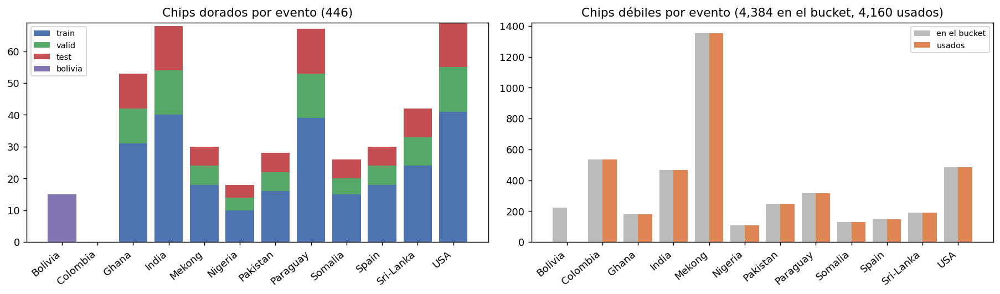


*Chips dorados por evento y partición (izquierda) y chips débiles por evento (derecha).*

Partición oficial: 252 chips dorados de entrenamiento, 89 de validación, 90 de test (eventos vistos) y 15 de Bolivia (evento reservado). Para el entregable 2a se usan 4,160 chips débiles con etiqueta Otsu de Sentinel-1 y 4,160 con etiqueta por índice espectral de Sentinel-2, que son las dos fuentes de etiquetas débiles del dataset.

**Ruido de las etiquetas débiles.** El dataset también trae la etiqueta Otsu de los chips dorados (S1OtsuLabelHand), así que se puede comparar directamente con la etiqueta manual: IoU = 0.485, precisión = 0.609 y recall = 0.704 en 431 chips (coinciden en el 92.2 % de los píxeles). En otras palabras, la umbralización marca más agua de la que realmente hay (más comisión que omisión). El ruido cambia bastante entre eventos: el peor es Somalia (IoU 0.151) y el mejor Mekong (IoU 0.780). Las etiquetas débiles son muchas pero imperfectas, y eso es lo que se pone a prueba en el entregable 2a. Para las etiquetas débiles de Sentinel-2 el dataset no trae una versión sobre los chips dorados, así que su calidad solo se puede ver de forma indirecta en los resultados del 2a.


In [ ]:
mostrar("Contexto")

### 10.2 Entregable 1: U-Net y entrenamiento
Arquitectura, número de parámetros, protocolo de entrenamiento y criterio para elegir el modelo final, con las curvas de entrenamiento de todos los modelos.


La U-Net está escrita desde cero en PyTorch, sin librerías de segmentación. Tiene 4 niveles de submuestreo, 32 canales en el primer nivel y 7.85 M de parámetros. Como entrada usa VV y VH en dB, normalizados a [0, 1]. Se entrena con recortes aleatorios de 256x256 px a resolución nativa (10 m), volteos y rotaciones de 90°, y se evalúa sobre el chip completo de 512x512. Optimizador AdamW (lr=0.001, weight decay=0.0001) con cosine annealing, 40 épocas por modelo y batch de 8. Los píxeles sin dato (SAR vacío o etiqueta -1) no cuentan en la pérdida ni en las métricas. De cada modelo se guarda la época con mayor IoU en la validación dorada, y el umbral de decisión se elige maximizando F1 en validación; el test y Bolivia solo se usan para reportar. El modelo final es el de mayor IoU en validación: **Dorados + débiles S2 (índice)**.


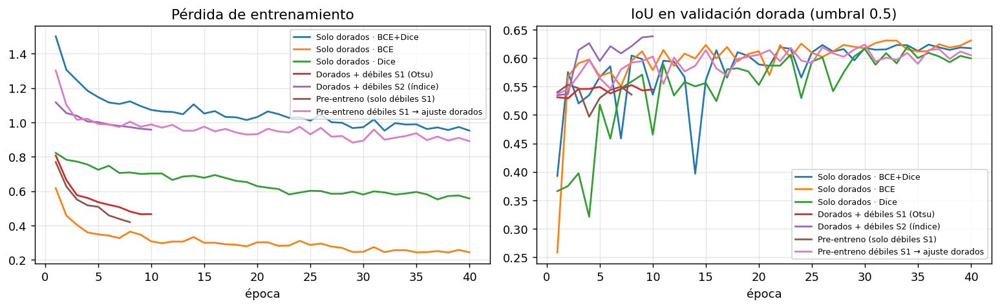


*Curvas de entrenamiento: pérdida y IoU de validación por época de cada modelo.*


In [ ]:
mostrar("Entregable 1")

### 10.3 Entregable 2a: solo dorados vs. dorados + débiles
De los 446 chips dorados, solo los 252 de entrenamiento se usan para ajustar pesos: los de validación sirven para elegir la época y el umbral, y los de test y Bolivia solo para evaluar. Se comparan cuatro estrategias con la misma U-Net y la misma pérdida (BCE+Dice):
1. Solo chips dorados.
2. Dorados + los 4,160 chips débiles con etiqueta Otsu de Sentinel-1.
3. Dorados + los 4,160 chips débiles con etiqueta por índice espectral de Sentinel-2.
4. Pre-entrenamiento con los débiles S1 y ajuste final con los dorados.

Todas se validan y evalúan solo con chips dorados, y la mejor se elige por IoU de validación.


Todas las estrategias usan la misma U-Net y la pérdida BCE+Dice, y se validan y evalúan solo con chips dorados: (1) solo los chips dorados de entrenamiento; (2) dorados + 4,160 chips débiles con etiqueta Otsu de Sentinel-1; (3) dorados + 4,160 chips débiles con etiqueta por índice de Sentinel-2; (4) pre-entrenamiento con los débiles S1 y ajuste final con los dorados. Con los débiles cada época tiene ~4,412 chips, por eso estos modelos se entrenan 10 épocas en lugar de 40 (aun así hacen más pasos de optimización).

*Estrategias de supervisión evaluadas en el test (eventos vistos).*

| Modelo                                  | Umbral   | IoU   | IoU medio/chip   | F1    | Precisión   | Recall   | Omisión   | Comisión   |
|:----------------------------------------|:---------|:------|:-----------------|:------|:------------|:---------|:----------|:-----------|
| Solo dorados · BCE+Dice                 | 0.50     | 0.656 | 0.406            | 0.792 | 0.772       | 0.813    | 0.187     | 0.228      |
| Dorados + débiles S1 (Otsu)             | 0.45     | 0.601 | 0.331            | 0.751 | 0.769       | 0.734    | 0.266     | 0.231      |
| Dorados + débiles S2 (índice)           | 0.45     | 0.669 | 0.422            | 0.802 | 0.775       | 0.831    | 0.169     | 0.225      |
| Pre-entreno débiles S1 → ajuste dorados | 0.60     | 0.652 | 0.392            | 0.790 | 0.778       | 0.801    | 0.199     | 0.222      |

*Las mismas estrategias evaluadas en Bolivia (evento no visto).*

| Modelo                                  | Umbral   | IoU   | IoU medio/chip   | F1    | Precisión   | Recall   | Omisión   | Comisión   |
|:----------------------------------------|:---------|:------|:-----------------|:------|:------------|:---------|:----------|:-----------|
| Solo dorados · BCE+Dice                 | 0.50     | 0.638 | 0.402            | 0.779 | 0.856       | 0.715    | 0.285     | 0.144      |
| Dorados + débiles S1 (Otsu)             | 0.45     | 0.699 | 0.427            | 0.823 | 0.871       | 0.780    | 0.220     | 0.129      |
| Dorados + débiles S2 (índice)           | 0.45     | 0.669 | 0.426            | 0.801 | 0.845       | 0.762    | 0.238     | 0.155      |
| Pre-entreno débiles S1 → ajuste dorados | 0.60     | 0.671 | 0.417            | 0.803 | 0.877       | 0.741    | 0.259     | 0.123      |


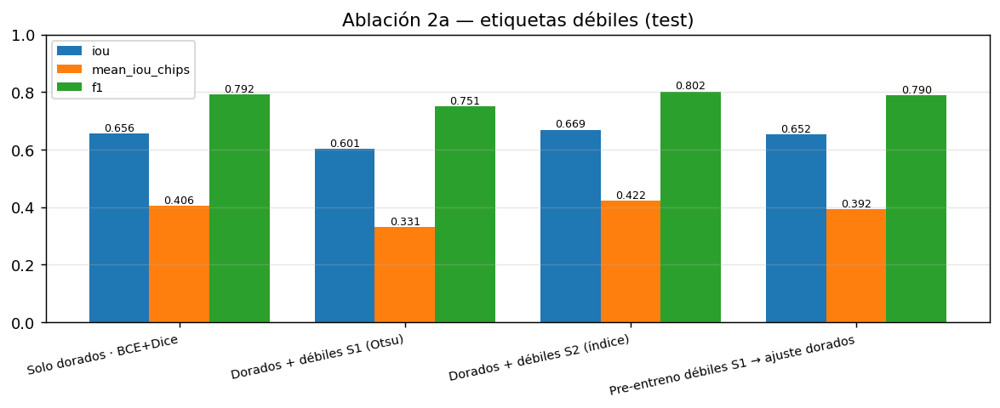


*Entregable 2a: IoU en test de cada estrategia de supervisión.*

- **Dorados + débiles S1 (Otsu)** frente a solo dorados: ΔIoU test -0.054, ΔIoU Bolivia +0.061, IoU de validación 0.553 (solo dorados: 0.624)
- **Dorados + débiles S2 (índice)** frente a solo dorados: ΔIoU test +0.013, ΔIoU Bolivia +0.031, IoU de validación 0.640 (solo dorados: 0.624)
- **Pre-entreno débiles S1 → ajuste dorados** frente a solo dorados: ΔIoU test -0.003, ΔIoU Bolivia +0.033, IoU de validación 0.626 (solo dorados: 0.624)

Según la validación, la mejor estrategia es **Dorados + débiles S2 (índice)**. Las etiquetas débiles S1 tienen en promedio 16.5 % de agua (S2: 13.5 %) y la etiqueta Otsu tiene un IoU de 0.485 frente a la etiqueta manual: aportan muchos más ejemplos y más variedad de eventos, pero con errores sistemáticos en bordes, sombras y vegetación. De las dos fuentes de etiquetas débiles, las **débiles S2 (índice)** dan mejor resultado en validación (0.553 S1 vs. 0.640 S2). Una explicación es que las etiquetas S1 salen del mismo radar y heredan sus errores (sombras, doble rebote), que el modelo termina aprendiendo; las S2 no dependen del radar, aunque sí de que la escena óptica esté despejada y de que su fecha coincida con la del SAR. La idea del pre-entrenamiento con ajuste es aprovechar la cantidad de datos débiles para aprender patrones generales de retrodispersión y dejar que al final las etiquetas manuales corrijan los sesgos de la umbralización; al mezclarlos con los dorados, en cambio, el modelo ve ese ruido durante todo el entrenamiento. En nuestros resultados la supervisión débil **mejora** al modelo que solo usa chips dorados, así que vale la pena usarla.


In [ ]:
mostrar("Entregable 2a")

### 10.4 Entregable 2b: BCE vs. Dice vs. BCE+Dice
Tres modelos con los mismos chips dorados, la misma arquitectura y las mismas épocas; solo cambia la pérdida. El umbral de cada uno se elige en validación.


*Comparación de pérdidas (solo chips dorados, mismas épocas; umbral elegido en validación).*

| Modelo                  | Umbral   | IoU   | IoU medio/chip   | F1    | Precisión   | Recall   | Omisión   | Comisión   |
|:------------------------|:---------|:------|:-----------------|:------|:------------|:---------|:----------|:-----------|
| Solo dorados · BCE      | 0.50     | 0.671 | 0.394            | 0.803 | 0.801       | 0.805    | 0.195     | 0.199      |
| Solo dorados · Dice     | 0.10     | 0.635 | 0.390            | 0.777 | 0.745       | 0.812    | 0.188     | 0.255      |
| Solo dorados · BCE+Dice | 0.50     | 0.656 | 0.406            | 0.792 | 0.772       | 0.813    | 0.187     | 0.228      |


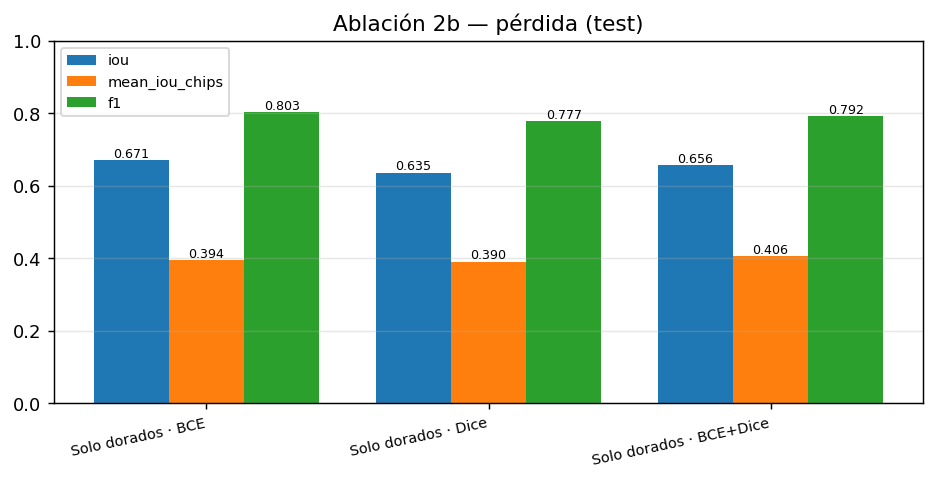


*Comparación de pérdidas en test.*

**Solo dorados · BCE** es el mejor tanto en validación, que es el criterio de selección (IoU 0.631), como en test (IoU 0.671). La BCE con pos_weight=3.0 logra precisión 0.801 y recall 0.805, y la Dice 0.745 y 0.812. La BCE promedia el error de todos los píxeles y, como hay ~8 píxeles válidos por cada píxel de agua, sin el pos_weight su gradiente quedaría dominado por la tierra. La Dice mide directamente el solapamiento de la clase agua y no depende de los verdaderos negativos, así que en principio maneja mejor el desbalance. La combinación busca juntar el gradiente estable de la BCE con el enfoque en el solapamiento de la Dice.


In [ ]:
mostrar("Entregable 2b")

### 10.5 Entregable 3: evaluación en distribución
Métricas del modelo final en el test oficial (90 chips de los 10 eventos que se vieron en entrenamiento), barrido del umbral, matriz de confusión con su comentario, IoU por evento y ejemplos.


*Métricas de la clase agua en test del modelo final (umbral 0.45).*

| Modelo                        | Umbral   | IoU   | IoU medio/chip   | F1    | Precisión   | Recall   | Omisión   | Comisión   |
|:------------------------------|:---------|:------|:-----------------|:------|:------------|:---------|:----------|:-----------|
| Dorados + débiles S2 (índice) | 0.45     | 0.669 | 0.422            | 0.802 | 0.775       | 0.831    | 0.169     | 0.225      |


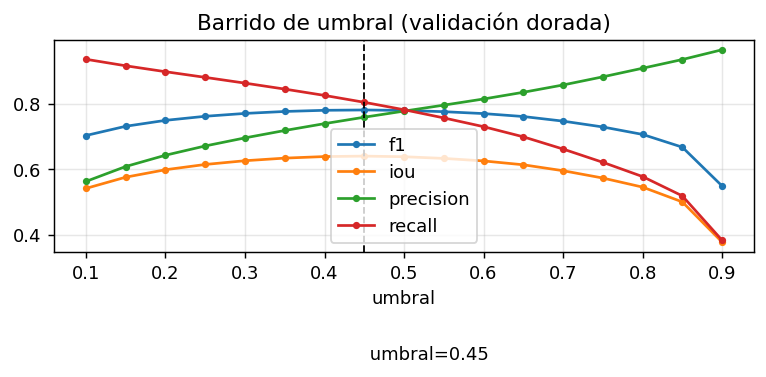


*Barrido del umbral de decisión en validación; la línea discontinua marca el umbral elegido.*


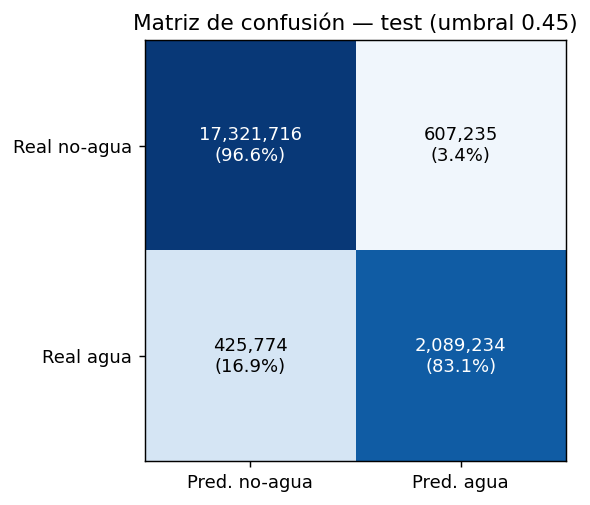


*Matriz de confusión por píxel en el test (conteos y porcentaje por fila).*

**Comentario de la matriz de confusión.** El agua es solo el 12.3 % de los 20,443,959 píxeles válidos del test, así que la exactitud no dice mucho: un modelo que nunca predijera agua tendría 87.7 % de exactitud (el nuestro tiene 94.9 %). Por eso usamos métricas de la clase agua. De cada 100 píxeles de agua real el modelo detecta 83 y se le escapan 17; de cada 100 píxeles que marca como agua, 77 lo son. Hay 0.29 falsos positivos por cada verdadero positivo y la **comisión** (falsas alarmas) es mayor que la omisión, así que el modelo tiende a marcar agua de más. El IoU agregado es 0.669 (IC 95 % por bootstrap sobre chips: 0.560-0.748) y el IoU promedio por chip es 0.422: la diferencia indica que al modelo le va bien en los chips con mucha agua y peor en los que tienen poca, que en el promedio por chip pesan lo mismo.

*IoU agregado del modelo final por evento de inundación en el test.*

| Evento    | Chips   | IoU   | Órbita S1   |
|:----------|:--------|:------|:------------|
| Pakistan  | 6       | 0.255 | DESCENDING  |
| USA       | 14      | 0.560 | ASCENDING   |
| Somalia   | 6       | 0.582 | ASCENDING   |
| Ghana     | 11      | 0.583 | ASCENDING   |
| Paraguay  | 14      | 0.639 | DESCENDING  |
| Spain     | 6       | 0.696 | DESCENDING  |
| India     | 14      | 0.724 | DESCENDING  |
| Sri-Lanka | 9       | 0.815 | DESCENDING  |
| Mekong    | 6       | 0.852 | ASCENDING   |
| Nigeria   | 4       | 0.882 | ASCENDING   |

El evento más difícil es **Pakistan** (IoU 0.255) y el más fácil **Nigeria** (IoU 0.882).


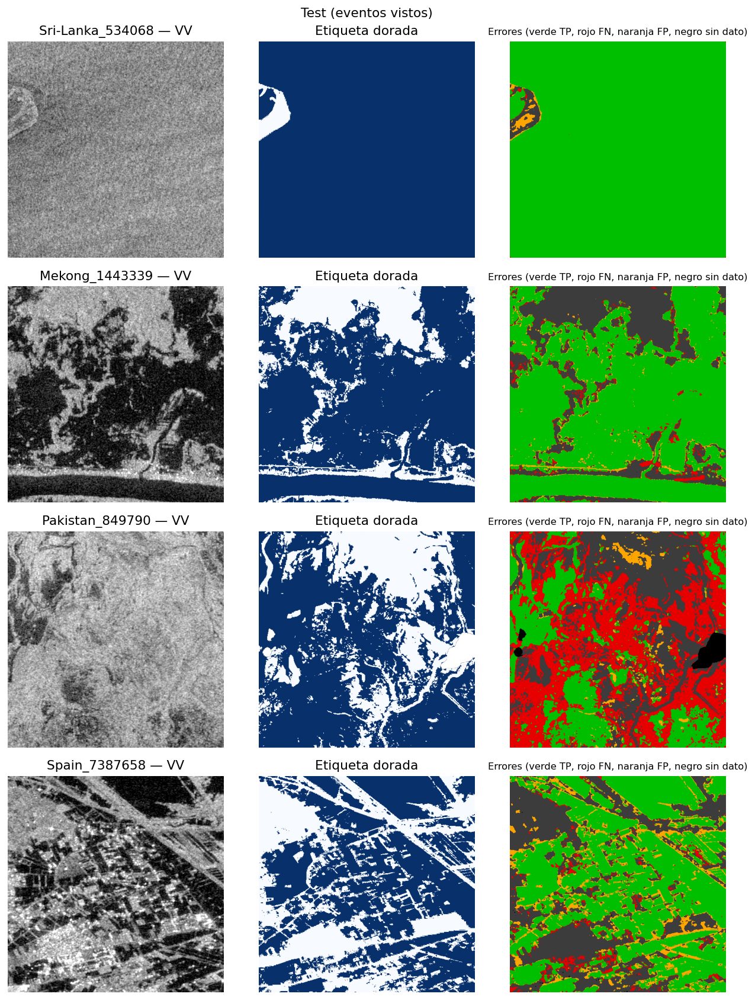


*Ejemplos del test: VV, etiqueta dorada y mapa de errores.*


In [ ]:
mostrar("Entregable 3")

### 10.6 Entregable 4: generalización geográfica (Bolivia)
La partición oficial ya deja a Bolivia fuera de entrenamiento y validación, y sus chips débiles no se descargan, así que todos los modelos cumplen esa condición. Se muestra la brecha entre test y Bolivia con su intervalo de confianza y cinco hipótesis revisadas con datos.


*Brecha de generalización del modelo final, Dorados + débiles S2 (índice).*

| Métrica        | Test   | Bolivia   | Brecha   |
|:---------------|:-------|:----------|:---------|
| IoU            | 0.669  | 0.669     | -0.000   |
| IoU medio/chip | 0.422  | 0.426     | +0.004   |
| F1             | 0.802  | 0.801     | -0.000   |
| Precisión      | 0.775  | 0.845     | +0.070   |
| Recall         | 0.831  | 0.762     | -0.068   |


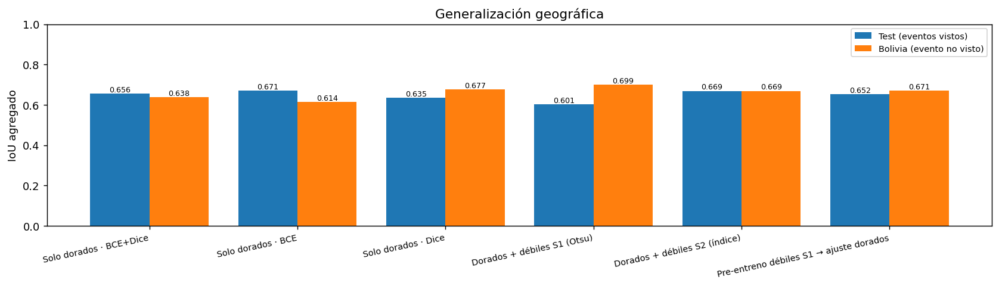


*IoU en test y en Bolivia de todos los modelos.*


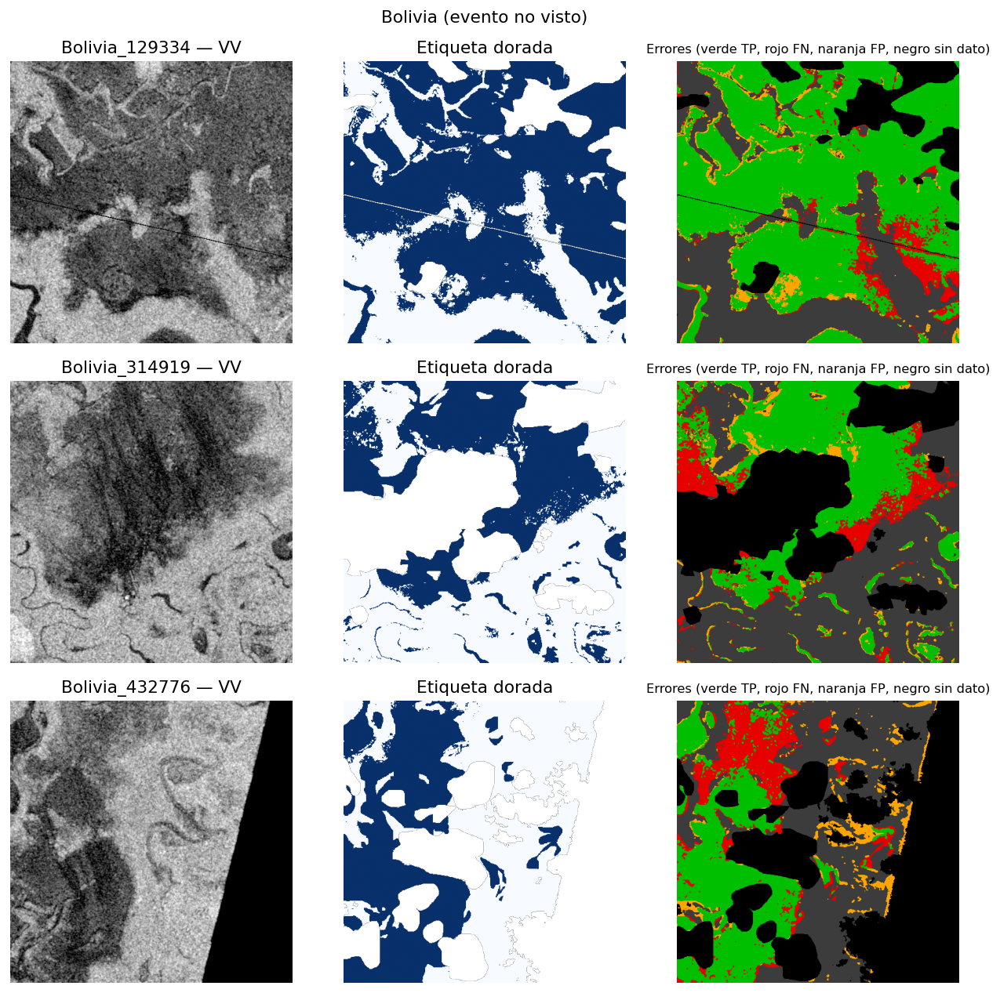


*Ejemplos de Bolivia: VV, etiqueta dorada y mapa de errores.*

Siguiendo la partición oficial, ningún chip de Bolivia (dorado o débil) se usó para entrenar ni para elegir hiperparámetros. El IoU en Bolivia es 0.669 (IC 95 %: 0.479-0.772) y en el test 0.669, una brecha de -0.000. Los intervalos de confianza se solapan, así que con solo 15 chips la diferencia no es estadísticamente concluyente. En la práctica el modelo rinde igual en Bolivia que en los eventos vistos, aunque nunca vio esa zona al entrenar.

*Composición del test y de Bolivia (datos para revisar las hipótesis).*

| Conjunto   | Chips   | Eventos   | Frac. agua   | Chips sin agua   | VV agua   | VV tierra   | Contraste   | Agua brillante   |
|:-----------|:--------|:----------|:-------------|:-----------------|:----------|:------------|:------------|:-----------------|
| test       | 90      | 10        | 12.3 %       | 8                | -17.6 dB  | -9.5 dB     | 8.1 dB      | 25.7 %           |
| bolivia    | 15      | 1         | 16.0 %       | 0                | -16.5 dB  | -8.4 dB     | 8.1 dB      | 13.3 %           |

**Hipótesis sobre la brecha**, cada una comparada con los datos de la tabla anterior:

- **Composición y tamaño de los cuerpos de agua.** Fracción de agua: test 12.3 % vs. Bolivia 16.0 %; chips sin agua: 8 vs. 0. Las superficies de agua grandes y continuas (como las llanuras inundadas de la Amazonía boliviana) son más fáciles de segmentar que los parches pequeños, porque los errores de borde pesan menos frente al área total; y en un chip sin agua solo se pueden cometer falsas alarmas. Este factor favorece a Bolivia y puede compensar que sea un evento nuevo.
- **Contraste radiométrico.** Diferencia mediana de VV entre tierra y agua: 8.1 dB en test vs. 8.1 dB en Bolivia. Con más contraste, el agua (lisa y oscura) se separa mejor de la tierra (más brillante). La diferencia es pequeña, así que este factor por sí solo no explica la brecha.
- **Cobertura del suelo: zonas urbanas y vegetación inundada.** Porcentaje del agua con VV > -12 dB (agua 'brillante', típica del doble rebote en ciudades o con vegetación que sobresale): test 25.7 % vs. Bolivia 13.3 %. Esa agua es casi invisible para un modelo que se basa en la retrodispersión. Este factor favorece a Bolivia y puede compensar que sea un evento nuevo. El evento más difícil del test es Pakistan (IoU 0.255).
- **Geometría de adquisición y ángulo de incidencia.** La escena de Bolivia es de órbita DESCENDING (órbita relativa 156). El ángulo de incidencia cambia a lo ancho del swath de Sentinel-1 y modifica la retrodispersión de la tierra y del agua, así que el umbral que el modelo aprende en otros eventos puede encajar mejor o peor en una escena nueva. Los chips no traen el ángulo, por lo que no se puede comprobar aquí; habría que agregarlo como canal de entrada.
- **Varianza por tamaño de muestra.** Bolivia tiene solo 15 chips; el IC bootstrap (0.479-0.772) muestra cuánto puede moverse la métrica según qué chips entren.


In [ ]:
mostrar("Entregable 4")

### 10.7 Entregable 5: errores característicos del SAR
Primero, qué porcentaje de los errores del test corresponde a cada tipo. Después, un chip de ejemplo por tipo con cinco paneles: VV, VH, Sentinel-2 en color natural, mapa de errores e histograma de retrodispersión.


Cada píxel mal clasificado del test se asignó a un tipo de error con reglas simples sobre VV y la distancia al agua: FP oscuros (VV < -15 dB) a más de 50 m del agua real (sombra de radar o superficies muy lisas), FP en la franja de 50 m alrededor del agua (suelo saturado y píxeles mixtos), FN brillantes (VV > -12 dB: doble rebote en zonas urbanas o vegetación inundada), FN dentro del agua con VV intermedio (-16 a -12 dB: agua rugosa por viento o con sedimentos) y FN dentro del agua con VV oscuro (el agua tiene su firma típica pero el modelo no la marca, por ejemplo en cuerpos de agua muy pequeños o aislados).


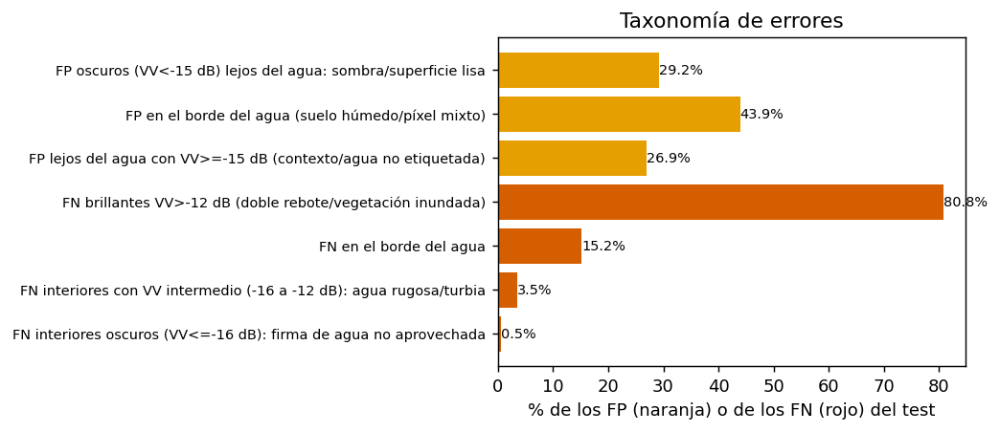


*Distribución de los errores del test por tipo.*

- FP oscuros (VV<-15 dB) lejos del agua: sombra/superficie lisa: 29.2 %
- FP en el borde del agua (suelo húmedo/píxel mixto): 43.9 %
- FP lejos del agua con VV>=-15 dB (contexto/agua no etiquetada): 26.9 %
- FN brillantes VV>-12 dB (doble rebote/vegetación inundada): 80.8 %
- FN en el borde del agua: 15.2 %
- FN interiores con VV intermedio (-16 a -12 dB): agua rugosa/turbia: 3.5 %
- FN interiores oscuros (VV<=-16 dB): firma de agua no aprovechada: 0.5 %

**A) Comisión: superficie oscura lejos del agua (sombra de radar / superficie lisa)** (chip Pakistan_70625). En este chip el VV mediano del agua bien detectada es -15.6 dB y el de la tierra bien clasificada -8.5 dB. Hay 33,063 falsos positivos oscuros a más de 50 m del agua real, con VV mediano -17.6 dB, prácticamente igual al del agua: al sensor le llega tan poca señal como desde agua abierta. Esto pasa en laderas que quedan ocultas para el radar (sombra de radar) y en superficies lisas como pistas o suelo desnudo húmedo o recién arado, que reflejan el pulso lejos del satélite. En Sentinel-2 esos píxeles tienen MNDWI mediano -0.231 (negativo: en el óptico no parecen agua; en el agua bien detectada: 0.050) y NDVI 0.051 (suelo desnudo, zona urbana o agua). Para separarlos haría falta información adicional (modelo de elevación, Sentinel-2 o series de tiempo).


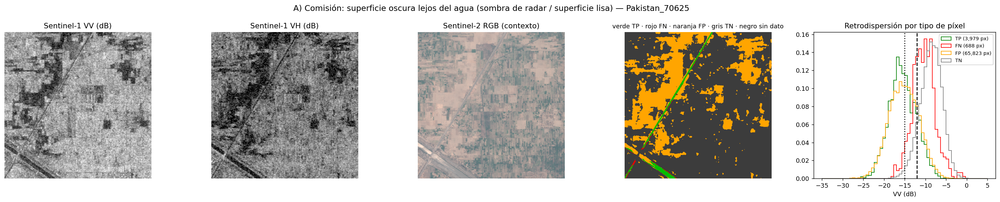


*A) Comisión: superficie oscura lejos del agua (sombra de radar / superficie lisa)*

**B) Omisión: agua con retrodispersión alta (doble rebote / vegetación inundada)** (chip Pakistan_849790). En este chip el VV mediano del agua bien detectada es -14.3 dB y el de la tierra bien clasificada -8.0 dB. Hay 103,067 falsos negativos con VV > -12 dB (mediana -8.2 dB, +6.1 dB respecto al agua detectada). Si hay estructuras verticales sobre el agua, el pulso rebota en el agua, luego en una pared o un tronco, y vuelve al sensor (doble rebote): el agua se ve brillante y el modelo la confunde con tierra. En Sentinel-2 esos píxeles tienen MNDWI mediano 0.203 (positivo: en el óptico parecen agua o suelo muy húmedo; en el agua bien detectada: 0.400) y NDVI 0.075 (suelo desnudo, zona urbana o agua). Un NDVI bajo con retrodispersión alta es compatible con zonas urbanas inundadas.


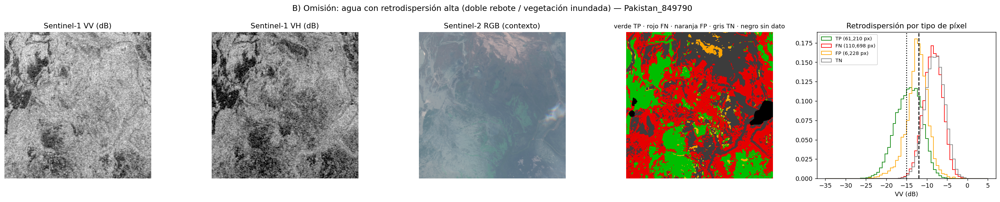


*B) Omisión: agua con retrodispersión alta (doble rebote / vegetación inundada)*

**C) Confusión en el borde agua–suelo húmedo** (chip Spain_7387658). En este chip el VV mediano del agua bien detectada es -19.8 dB y el de la tierra bien clasificada -8.5 dB. 29,950 de los 41,130 errores del chip (72.8 %) están a menos de 50 m del borde del agua real, con VV mediano -12.4 dB. En esa franja el suelo saturado tiene una retrodispersión intermedia, los píxeles de 10 m mezclan agua y tierra y hasta la etiqueta manual es dudosa; el speckle del SAR empeora la confusión. En Sentinel-2 esos píxeles tienen MNDWI mediano 0.099 (positivo: en el óptico parecen agua o suelo muy húmedo; en el agua bien detectada: 0.604) y NDVI 0.205 (vegetación moderada).


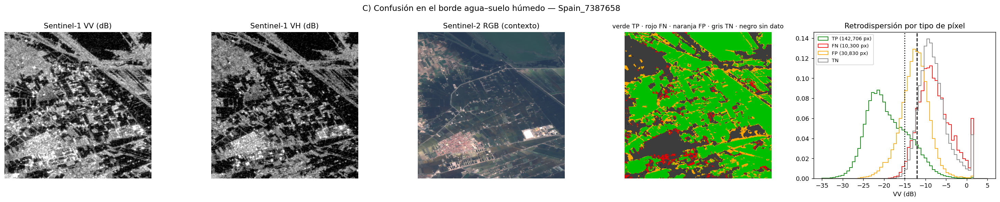


*C) Confusión en el borde agua–suelo húmedo*

**D) Omisión: agua con VV intermedio (rugosidad por viento / turbidez)** (chip Ghana_866994). En este chip el VV mediano del agua bien detectada es -18.9 dB y el de la tierra bien clasificada -9.4 dB. Hay 3,859 falsos negativos dentro del agua con VV intermedio (mediana -12.9 dB, entre el agua abierta y la tierra): el viento o la corriente vuelven rugosa la superficie y aumentan la retrodispersión, igual que los sedimentos en suspensión o la vegetación baja que sobresale. En Sentinel-2 esos píxeles tienen MNDWI mediano -0.056 (negativo: en el óptico no parecen agua; en el agua bien detectada: 0.293) y NDVI 0.196 (suelo desnudo, zona urbana o agua).


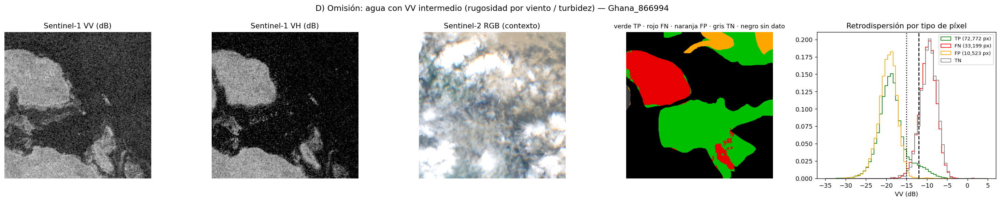


*D) Omisión: agua con VV intermedio (rugosidad por viento / turbidez)*


In [ ]:
mostrar("Entregable 5")

### 10.8 Entregable 6 (bono): fusión SAR + Sentinel-2
Los modelos de 2 y 15 canales se entrenan y evalúan con los mismos chips sin nubes, para que la comparación sea justa.

In [ ]:
mostrar("Entregable 6")


*Modelos entrenados y evaluados solo con chips sin nubes (los mismos para ambos).*

| Modelo                          | Umbral   | IoU   | IoU medio/chip   | F1    | Precisión   | Recall   | Omisión   | Comisión   |
|:--------------------------------|:---------|:------|:-----------------|:------|:------------|:---------|:----------|:-----------|
| Sin nubes · SAR (2 canales)     | 0.40     | 0.642 | 0.410            | 0.782 | 0.726       | 0.847    | 0.153     | 0.274      |
| Sin nubes · SAR+S2 (15 canales) | 0.45     | 0.875 | 0.658            | 0.933 | 0.928       | 0.938    | 0.062     | 0.072      |

Las imágenes S2Hand no traen máscara de nubes, así que se marcó como nube todo píxel con reflectancia azul > 0.2 y visible medio > 0.25, y se usaron los chips con menos de 5.0 % de nubes: 183 de train, 63 de validación y 66 de test. Para que la comparación sea justa, el modelo solo-SAR se volvió a entrenar con exactamente esos chips. Agregar las 13 bandas ópticas **mejora** el IoU en +0.233: el infrarrojo cercano y el SWIR separan el agua del suelo húmedo y de las sombras, que en el SAR se confunden. El problema en la práctica es que durante las tormentas casi no hay imágenes ópticas despejadas, que es justamente la razón para usar SAR.


### 10.9 Limitaciones

In [ ]:
mostrar("Limitaciones")


- Se usó una sola semilla por configuración, así que las diferencias pequeñas entre variantes pueden deberse a la variabilidad del entrenamiento.
- Bolivia tiene 15 chips, por lo que sus intervalos de confianza son anchos.
- Se usaron los 4,160 chips débiles disponibles fuera de Bolivia, pero por tiempo de cómputo los modelos con débiles se entrenaron 10 épocas (frente a 40 de los modelos solo con dorados); con más épocas el resultado del 2a podría cambiar.
- La etiqueta dorada también es incierta en bordes y zonas urbanas, lo que limita el IoU que se puede alcanzar.
- El filtro de nubes de Sentinel-2 es una regla aproximada (S2Hand no trae máscara de nubes).
- No se usa el ángulo de incidencia ni un modelo de elevación, que ayudarían a descartar sombras de radar.

---
## 11. Empaquetar la entrega
Crea `sen1floods11_p2_entrega.zip` (se descarga y se copia a Drive) con:
- `sen1floods11_unet/`: el repositorio (código, `README.md` con resultados y `requirements.txt`).
- `outputs/`: resultados en JSON y CSV, figuras, `analisis.md`, el informe `informe/informe_p2.tex` con sus figuras y el checkpoint del modelo final.

In [ ]:
import shutil, zipfile
final_tag = R["models"][R["final_model"]]["tag"]
zip_path = Path("sen1floods11_p2_entrega.zip")
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for p in Path("sen1floods11_unet").rglob("*"):
        if p.is_file() and "__pycache__" not in p.parts:
            z.write(p, p.as_posix())
    for p in OUT_DIR.rglob("*"):
        if p.is_file() and (p.parent.name != "checkpoints" or p.stem == final_tag):
            z.write(p, "outputs/" + p.relative_to(OUT_DIR).as_posix())
print(f"Zip creado: {zip_path} ({zip_path.stat().st_size / 1e6:.1f} MB)")
try:
    shutil.copy(zip_path, OUT_DIR.parent / zip_path.name)
    from google.colab import files
    files.download(str(zip_path))
except Exception as e:
    print("No se pudo descargar automáticamente (bajarlo desde el panel de archivos):", e)

Zip creado: sen1floods11_p2_entrega.zip (45.5 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>